# 11 — Patient-specific neural CT rendering

This notebook fits an **implicit neural representation (INR)** directly to the anonymized patient's CT volume. The network learns a continuous function

\[
f(x,y,z) \rightarrow (\mathrm{HU}_{brain\ window},\;\mathrm{HU}_{wide\ window})
\]

instead of learning only an outer surface. TotalSegmentator masks are reused only as anatomical regions of interest; no TotalSegmentator inference is performed here.

Outputs include:

- held-out-slice MAE, RMSE, PSNR and SSIM;
- a linear-interpolation reference for context;
- an original-versus-neural slice comparison;
- an interactive neural 3D cutaway containing skull, brain envelope and low-attenuation internal regions;
- an interactive neural CT volume;
- the trained neural-field weights and reconstructed NIfTI volume.

> Research visualization only. Low attenuation is not a diagnosis and should be interpreted by a qualified clinician.

In [1]:
from __future__ import annotations

import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch
import torch.nn as nn
import trimesh
from IPython.display import IFrame, display
from scipy import ndimage
from skimage import measure
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

PROJECT_ROOT = Path(r"F:\csstdy")
SOURCE_DIR = PROJECT_ROOT / "outputs" / "09_totalsegmentator_dl_skull_brain"
CT_PATH = SOURCE_DIR / "input" / "CASE_001_brain_kernel_ct.nii.gz"
BRAIN_MASK_PATH = SOURCE_DIR / "segmentations" / "brain.nii.gz"
SKULL_MASK_PATH = SOURCE_DIR / "segmentations" / "skull.nii.gz"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "11_neural_ct_rendering"
MODEL_DIR = OUTPUT_DIR / "model"
VOLUME_DIR = OUTPUT_DIR / "volumes"
FIGURE_DIR = OUTPUT_DIR / "figures"
for directory in (OUTPUT_DIR, MODEL_DIR, VOLUME_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Native-resolution reconstruction settings for the RTX 4060. Training still uses sampled coordinates.
DOWNSAMPLE = 1
CROP_MARGIN = 8
HELD_OUT_EVERY = 9
TRAIN_STEPS = 3600
BATCH_SIZE = 32768
LEARNING_RATE = 2.0e-4
HIDDEN_FEATURES = 128
HIDDEN_LAYERS = 4
INFERENCE_CHUNK = 262_144

SOFT_WINDOW = (-100.0, 150.0)    # emphasizes brain/CSF contrast
WIDE_WINDOW = (-1000.0, 2000.0)  # retains air, soft tissue and bone

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Output:", OUTPUT_DIR)

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
PyTorch: 2.14.0+cu130
Output: F:\csstdy\outputs\11_neural_ct_rendering


## 1. Load, crop and prepare the patient volume

The bounding box is derived from the union of the brain and skull masks. The neural field is evaluated at the native CT resolution while retaining the original physical coordinate system. Every ninth axial plane is excluded from training and used only for evaluation.

In [2]:
for required_path in (CT_PATH, BRAIN_MASK_PATH, SKULL_MASK_PATH):
    if not required_path.exists():
        raise FileNotFoundError(required_path)

ct_img = nib.load(CT_PATH)
brain_img = nib.load(BRAIN_MASK_PATH)
skull_img = nib.load(SKULL_MASK_PATH)

ct_full = np.asarray(ct_img.dataobj, dtype=np.float32)
brain_full = np.asarray(brain_img.dataobj) > 0
skull_full = np.asarray(skull_img.dataobj) > 0

if ct_full.shape != brain_full.shape or ct_full.shape != skull_full.shape:
    raise ValueError("CT, brain and skull volumes must have the same shape.")
if not (np.allclose(ct_img.affine, brain_img.affine) and np.allclose(ct_img.affine, skull_img.affine)):
    raise ValueError("CT and masks do not share the same affine.")

anatomy_full = brain_full | skull_full
positions = np.where(anatomy_full)
lower = np.maximum([int(axis.min()) for axis in positions], 0)
upper = np.minimum([int(axis.max()) + 1 for axis in positions], ct_full.shape)
lower = np.maximum(lower - CROP_MARGIN, 0)
upper = np.minimum(upper + CROP_MARGIN, ct_full.shape)
crop_slices = tuple(slice(int(lo), int(hi), DOWNSAMPLE) for lo, hi in zip(lower, upper))

ct = np.ascontiguousarray(ct_full[crop_slices], dtype=np.float32)
brain = np.ascontiguousarray(brain_full[crop_slices])
skull = np.ascontiguousarray(skull_full[crop_slices])
anatomy = brain | skull
head_roi = ndimage.binary_dilation(anatomy, iterations=2)

# Map the sampled crop back into patient/world millimetres.
crop_transform = np.eye(4, dtype=np.float64)
crop_transform[:3, :3] = np.diag([DOWNSAMPLE] * 3)
crop_transform[:3, 3] = lower
crop_affine = ct_img.affine @ crop_transform

held_z = np.arange(4, ct.shape[2] - 4, HELD_OUT_EVERY, dtype=np.int64)
held_planes = np.zeros(ct.shape[2], dtype=bool)
held_planes[held_z] = True
train_planes = ~held_planes

print("Original shape:", ct_full.shape, "voxel spacing (mm):", ct_img.header.get_zooms()[:3])
print("Neural-field crop:", tuple(lower), "to", tuple(upper))
print("Working shape:", ct.shape, "effective spacing (mm):", tuple(np.asarray(ct_img.header.get_zooms()[:3]) * DOWNSAMPLE))
print("Held-out axial planes:", held_z.tolist())
print("Brain voxels:", int(brain.sum()), "Skull voxels:", int(skull.sum()))

Original shape: (512, 512, 227) voxel spacing (mm): (np.float32(0.5557461), np.float32(0.5557461), np.float32(0.75))
Neural-field crop: (np.int64(92), np.int64(106), np.int64(0)) to (np.int64(352), np.int64(428), np.int64(223))
Working shape: (260, 322, 223) effective spacing (mm): (np.float32(0.5557461), np.float32(0.5557461), np.float32(0.75))
Held-out axial planes: [4, 13, 22, 31, 40, 49, 58, 67, 76, 85, 94, 103, 112, 121, 130, 139, 148, 157, 166, 175, 184, 193, 202, 211]
Brain voxels: 4975324 Skull voxels: 2496034


In [3]:
def hu_to_unit(values: np.ndarray, window: tuple[float, float]) -> np.ndarray:
    lo, hi = window
    return np.clip((values - lo) / (hi - lo), 0.0, 1.0).astype(np.float32)


def unit_to_hu(values: np.ndarray, window: tuple[float, float]) -> np.ndarray:
    lo, hi = window
    return values * (hi - lo) + lo


soft_target = hu_to_unit(ct, SOFT_WINDOW)
wide_target = hu_to_unit(ct, WIDE_WINDOW)

# Physical coordinates, centred and scaled isotropically to approximately [-1, 1].
grid = np.indices(ct.shape, dtype=np.float32).reshape(3, -1).T
world_xyz = nib.affines.apply_affine(crop_affine, grid).astype(np.float32)
world_center = (world_xyz.min(axis=0) + world_xyz.max(axis=0)) / 2.0
world_scale = float(np.max(world_xyz.max(axis=0) - world_xyz.min(axis=0)) / 2.0)

def flat_ids(mask: np.ndarray) -> torch.Tensor:
    return torch.from_numpy(np.flatnonzero(mask.reshape(-1))).to(DEVICE)

train_plane_mask = np.broadcast_to(train_planes[None, None, :], ct.shape)
brain_pool = flat_ids(brain & train_plane_mask)
skull_pool = flat_ids(skull & train_plane_mask)
context_pool = flat_ids(head_roi & train_plane_mask & ~brain & ~skull)

soft_gpu = torch.from_numpy(soft_target.reshape(-1)).to(DEVICE)
wide_gpu = torch.from_numpy(wide_target.reshape(-1)).to(DEVICE)
shape_gpu = torch.tensor(ct.shape, device=DEVICE, dtype=torch.long)
affine_gpu = torch.tensor(crop_affine, device=DEVICE, dtype=torch.float32)
center_gpu = torch.tensor(world_center, device=DEVICE, dtype=torch.float32)

def ids_to_coordinates(ids: torch.Tensor) -> torch.Tensor:
    yz = shape_gpu[1] * shape_gpu[2]
    ix = torch.div(ids, yz, rounding_mode="floor")
    remainder = ids - ix * yz
    iy = torch.div(remainder, shape_gpu[2], rounding_mode="floor")
    iz = remainder - iy * shape_gpu[2]
    ijk = torch.stack((ix, iy, iz), dim=1).float()
    xyz = ijk @ affine_gpu[:3, :3].T + affine_gpu[:3, 3]
    return (xyz - center_gpu) / world_scale

print("Training pools — brain:", brain_pool.numel(), "skull:", skull_pool.numel(), "context:", context_pool.numel())

Training pools — brain: 4423112 skull: 2218109 context: 544202


## 2. Fit a dual-window SIREN neural field

The model is trained on patient-space coordinates. Balanced sampling gives subtle intracranial contrast enough influence without losing the high-HU skull. Sine activations are used because they represent high-frequency spatial signals more effectively than a plain coordinate MLP.

In [4]:
class SineLayer(nn.Module):
    def __init__(self, in_features: int, out_features: int, *, first: bool = False, omega_0: float = 30.0):
        super().__init__()
        self.in_features = in_features
        self.first = first
        self.omega_0 = omega_0
        self.linear = nn.Linear(in_features, out_features)
        self.reset_parameters()

    def reset_parameters(self) -> None:
        with torch.no_grad():
            if self.first:
                bound = 1.0 / self.in_features
            else:
                bound = math.sqrt(6.0 / self.in_features) / self.omega_0
            self.linear.weight.uniform_(-bound, bound)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.sin(self.omega_0 * self.linear(x))


class DualWindowSIREN(nn.Module):
    def __init__(self, hidden_features: int = 128, hidden_layers: int = 4):
        super().__init__()
        layers: list[nn.Module] = [SineLayer(3, hidden_features, first=True, omega_0=30.0)]
        layers.extend(SineLayer(hidden_features, hidden_features, omega_0=30.0) for _ in range(hidden_layers))
        final = nn.Linear(hidden_features, 2)
        with torch.no_grad():
            bound = math.sqrt(6.0 / hidden_features) / 30.0
            final.weight.uniform_(-bound, bound)
        layers.extend([final, nn.Sigmoid()])
        self.network = nn.Sequential(*layers)

    def forward(self, xyz: torch.Tensor) -> torch.Tensor:
        return self.network(xyz)


model = DualWindowSIREN(HIDDEN_FEATURES, HIDDEN_LAYERS).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=TRAIN_STEPS, eta_min=2e-5)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(model)
print(f"Trainable parameters: {parameter_count:,}")

DualWindowSIREN(
  (network): Sequential(
    (0): SineLayer(
      (linear): Linear(in_features=3, out_features=128, bias=True)
    )
    (1): SineLayer(
      (linear): Linear(in_features=128, out_features=128, bias=True)
    )
    (2): SineLayer(
      (linear): Linear(in_features=128, out_features=128, bias=True)
    )
    (3): SineLayer(
      (linear): Linear(in_features=128, out_features=128, bias=True)
    )
    (4): SineLayer(
      (linear): Linear(in_features=128, out_features=128, bias=True)
    )
    (5): Linear(in_features=128, out_features=2, bias=True)
    (6): Sigmoid()
  )
)
Trainable parameters: 66,818


In [5]:
def draw(pool: torch.Tensor, count: int) -> torch.Tensor:
    return pool[torch.randint(0, pool.numel(), (count,), device=DEVICE)]


loss_history = []
start_time = time.perf_counter()
model.train()

for step in range(1, TRAIN_STEPS + 1):
    # 50% brain, 25% skull, 25% surrounding head context.
    n_brain = BATCH_SIZE // 2
    n_skull = BATCH_SIZE // 4
    ids = torch.cat((
        draw(brain_pool, n_brain),
        draw(skull_pool, n_skull),
        draw(context_pool, BATCH_SIZE - n_brain - n_skull),
    ))
    ids = ids[torch.randperm(ids.numel(), device=DEVICE)]
    coordinates = ids_to_coordinates(ids)
    targets = torch.stack((soft_gpu[ids], wide_gpu[ids]), dim=1)

    predictions = model(coordinates)
    soft_loss = torch.mean((predictions[:, 0] - targets[:, 0]) ** 2)
    wide_loss = torch.mean((predictions[:, 1] - targets[:, 1]) ** 2)
    loss = 0.65 * soft_loss + 0.35 * wide_loss

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    scheduler.step()

    if step == 1 or step % 100 == 0:
        elapsed = time.perf_counter() - start_time
        record = {
            "step": step,
            "loss": float(loss.detach().cpu()),
            "soft_mse": float(soft_loss.detach().cpu()),
            "wide_mse": float(wide_loss.detach().cpu()),
            "elapsed_seconds": elapsed,
        }
        loss_history.append(record)
        if step == 1 or step % 500 == 0 or step == TRAIN_STEPS:
            print(f"step {step:4d}/{TRAIN_STEPS} | loss {record['loss']:.6f} | elapsed {elapsed:.1f}s")

training_seconds = time.perf_counter() - start_time
print(f"Training completed in {training_seconds:.1f} seconds ({training_seconds / 60:.1f} minutes).")

checkpoint = {
    "model_state_dict": model.state_dict(),
    "architecture": "dual-window SIREN",
    "hidden_features": HIDDEN_FEATURES,
    "hidden_layers": HIDDEN_LAYERS,
    "soft_window_hu": SOFT_WINDOW,
    "wide_window_hu": WIDE_WINDOW,
    "world_center": world_center,
    "world_scale": world_scale,
    "crop_affine": crop_affine,
    "crop_lower_original_ijk": lower,
    "downsample": DOWNSAMPLE,
}
torch.save(checkpoint, MODEL_DIR / "CASE_001_dual_window_siren.pt")

step    1/3600 | loss 0.059439 | elapsed 0.2s


step  500/3600 | loss 0.003049 | elapsed 2.6s


step 1000/3600 | loss 0.001808 | elapsed 5.0s


step 1500/3600 | loss 0.001402 | elapsed 7.4s


step 2000/3600 | loss 0.001335 | elapsed 9.7s


step 2500/3600 | loss 0.001092 | elapsed 12.1s


step 3000/3600 | loss 0.000984 | elapsed 14.5s


step 3500/3600 | loss 0.000902 | elapsed 16.9s


step 3600/3600 | loss 0.000886 | elapsed 17.4s
Training completed in 17.5 seconds (0.3 minutes).


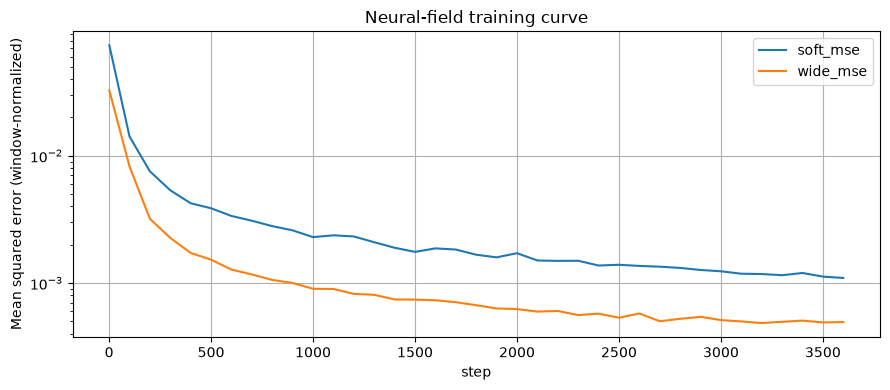

In [6]:
history = pd.DataFrame(loss_history)
ax = history.plot(x="step", y=["soft_mse", "wide_mse"], logy=True, figsize=(9, 4), grid=True)
ax.set_title("Neural-field training curve")
ax.set_ylabel("Mean squared error (window-normalized)")
plt.tight_layout()
training_curve_path = FIGURE_DIR / "training_curve.png"
plt.savefig(training_curve_path, dpi=160)
plt.show()

## 3. Reconstruct the volume and calculate held-out metrics

The excluded axial planes were never sampled during optimization. Metrics are reported separately for the brain/soft-tissue window and the complete head/wide window. Linear interpolation between neighbouring observed slices is included as a reference rather than as a claimed competing clinical method.

In [7]:
model.eval()
number_of_voxels = int(np.prod(ct.shape))
prediction_unit = np.empty((number_of_voxels, 2), dtype=np.float32)
inference_start = time.perf_counter()

with torch.inference_mode():
    for start in range(0, number_of_voxels, INFERENCE_CHUNK):
        stop = min(start + INFERENCE_CHUNK, number_of_voxels)
        ids = torch.arange(start, stop, device=DEVICE)
        prediction_unit[start:stop] = model(ids_to_coordinates(ids)).cpu().numpy()

inference_seconds = time.perf_counter() - inference_start
prediction_unit = prediction_unit.reshape(*ct.shape, 2)
pred_soft_hu = unit_to_hu(prediction_unit[..., 0], SOFT_WINDOW).astype(np.float32)
pred_wide_hu = unit_to_hu(prediction_unit[..., 1], WIDE_WINDOW).astype(np.float32)

# Preserve air outside the evaluated head ROI in the exported volume.
predicted_hu = pred_wide_hu.copy()
predicted_hu[brain] = pred_soft_hu[brain]
predicted_hu[~head_roi] = -1000.0

neural_nifti_path = VOLUME_DIR / "CASE_001_neural_ct_reconstruction.nii.gz"
nib.save(nib.Nifti1Image(predicted_hu, crop_affine), neural_nifti_path)
np.savez_compressed(
    VOLUME_DIR / "CASE_001_neural_ct_windows.npz",
    soft_hu=pred_soft_hu,
    wide_hu=pred_wide_hu,
    brain_mask=brain,
    skull_mask=skull,
    affine=crop_affine,
)
print(f"Inference: {inference_seconds:.2f} seconds for {number_of_voxels:,} voxels")
print("Saved:", neural_nifti_path)

Inference: 1.41 seconds for 18,669,560 voxels
Saved: F:\csstdy\outputs\11_neural_ct_rendering\volumes\CASE_001_neural_ct_reconstruction.nii.gz


In [8]:
def linear_interpolation_reference(volume: np.ndarray, held_indices: np.ndarray) -> np.ndarray:
    reference = volume.copy()
    available = np.setdiff1d(np.arange(volume.shape[2]), held_indices)
    for z in held_indices:
        lower_candidates = available[available < z]
        upper_candidates = available[available > z]
        if not len(lower_candidates) or not len(upper_candidates):
            continue
        z0, z1 = int(lower_candidates[-1]), int(upper_candidates[0])
        weight = (z - z0) / (z1 - z0)
        reference[:, :, z] = (1.0 - weight) * volume[:, :, z0] + weight * volume[:, :, z1]
    return reference


linear_soft_hu = linear_interpolation_reference(np.clip(ct, *SOFT_WINDOW), held_z)
linear_wide_hu = linear_interpolation_reference(np.clip(ct, *WIDE_WINDOW), held_z)
held_volume_mask = np.broadcast_to(held_planes[None, None, :], ct.shape)

def scalar_metrics(target: np.ndarray, prediction: np.ndarray, mask: np.ndarray, data_range: float) -> dict:
    errors = prediction[mask] - target[mask]
    mse = float(np.mean(errors ** 2))
    return {
        "MAE_HU": float(np.mean(np.abs(errors))),
        "RMSE_HU": float(np.sqrt(mse)),
        "PSNR_dB": float(20.0 * np.log10(data_range / max(np.sqrt(mse), 1e-8))),
    }


def slice_ssim(target: np.ndarray, prediction: np.ndarray, mask: np.ndarray, z_indices: np.ndarray, window: tuple[float, float]) -> float:
    scores = []
    lo, hi = window
    for z in z_indices:
        slice_mask = mask[:, :, z]
        points = np.where(slice_mask)
        if not len(points[0]):
            continue
        x0, x1 = max(int(points[0].min()) - 3, 0), min(int(points[0].max()) + 4, target.shape[0])
        y0, y1 = max(int(points[1].min()) - 3, 0), min(int(points[1].max()) + 4, target.shape[1])
        target_slice = np.clip(target[x0:x1, y0:y1, z], lo, hi)
        prediction_slice = np.clip(prediction[x0:x1, y0:y1, z], lo, hi)
        scores.append(structural_similarity(target_slice, prediction_slice, data_range=hi - lo))
    return float(np.mean(scores))


metric_rows = []
for renderer, soft_prediction, wide_prediction in (
    ("Neural field", pred_soft_hu, pred_wide_hu),
    ("Linear slice interpolation", linear_soft_hu, linear_wide_hu),
):
    brain_eval = brain & held_volume_mask
    head_eval = head_roi & held_volume_mask

    brain_metrics = scalar_metrics(np.clip(ct, *SOFT_WINDOW), soft_prediction, brain_eval, SOFT_WINDOW[1] - SOFT_WINDOW[0])
    brain_metrics.update({
        "Method": renderer,
        "Region/window": "Brain, -100 to 150 HU",
        "SSIM": slice_ssim(ct, soft_prediction, brain, held_z, SOFT_WINDOW),
        "Evaluated_voxels": int(brain_eval.sum()),
    })
    metric_rows.append(brain_metrics)

    head_metrics = scalar_metrics(np.clip(ct, *WIDE_WINDOW), wide_prediction, head_eval, WIDE_WINDOW[1] - WIDE_WINDOW[0])
    head_metrics.update({
        "Method": renderer,
        "Region/window": "Head, -1000 to 2000 HU",
        "SSIM": slice_ssim(ct, wide_prediction, head_roi, held_z, WIDE_WINDOW),
        "Evaluated_voxels": int(head_eval.sum()),
    })
    metric_rows.append(head_metrics)

metrics_df = pd.DataFrame(metric_rows)[
    ["Method", "Region/window", "MAE_HU", "RMSE_HU", "PSNR_dB", "SSIM", "Evaluated_voxels"]
]
metrics_df.to_csv(OUTPUT_DIR / "held_out_metrics.csv", index=False)
display(metrics_df.round({"MAE_HU": 3, "RMSE_HU": 3, "PSNR_dB": 3, "SSIM": 4}))

,Method,Region/window,MAE_HU,RMSE_HU,PSNR_dB,SSIM,Evaluated_voxels
0,Neural field,"Brain, -100 to 150 HU",4.784,6.434,31.790,0.7179,552212
1,Neural field,"Head, -1000 to 2000 HU",36.942,73.743,32.188,0.6711,896762
2,Linear slice interpolation,"Brain, -100 to 150 HU",2.203,3.967,35.990,0.9202,552212
3,Linear slice interpolation,"Head, -1000 to 2000 HU",18.477,46.239,36.242,0.9671,896762


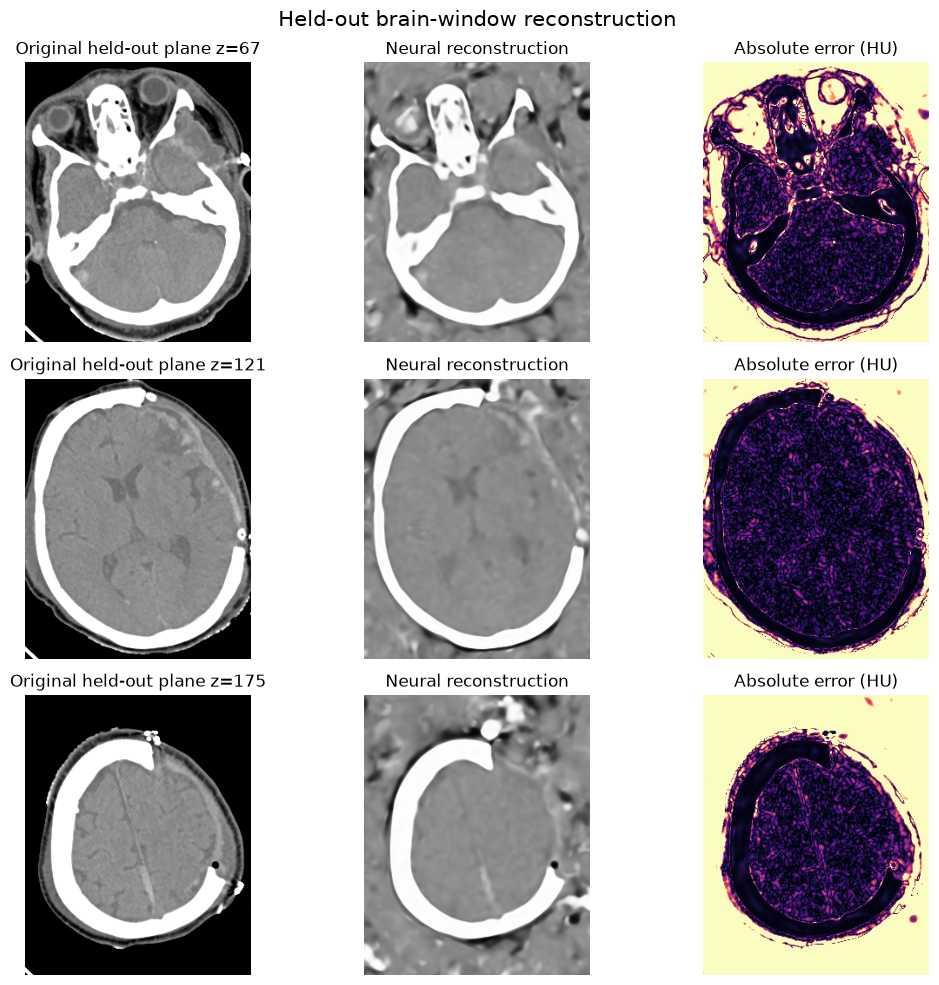

In [9]:
# Display representative held-out planes: original, neural prediction and absolute error.
brain_area_by_z = brain.sum(axis=(0, 1))
representative_pool = held_z[brain_area_by_z[held_z] >= np.percentile(brain_area_by_z[brain_area_by_z > 0], 35)]
selected_z = representative_pool[np.linspace(0, len(representative_pool) - 1, 3, dtype=int)]
fig, axes = plt.subplots(len(selected_z), 3, figsize=(11, 10))
for row, z in enumerate(selected_z):
    original = np.clip(ct[:, :, z], *SOFT_WINDOW)
    predicted = pred_soft_hu[:, :, z]
    error = np.abs(predicted - original)
    for axis, image, title, cmap, limits in (
        (axes[row, 0], original, f"Original held-out plane z={z}", "gray", SOFT_WINDOW),
        (axes[row, 1], predicted, "Neural reconstruction", "gray", SOFT_WINDOW),
        (axes[row, 2], error, "Absolute error (HU)", "magma", (0, 40)),
    ):
        axis.imshow(np.rot90(image), cmap=cmap, vmin=limits[0], vmax=limits[1])
        axis.axis("off")
        axis.set_title(title)
plt.suptitle("Held-out brain-window reconstruction", fontsize=15)
plt.tight_layout()
comparison_path = FIGURE_DIR / "held_out_slice_comparison.png"
plt.savefig(comparison_path, dpi=180, bbox_inches="tight")
plt.show()

## 4. Build the interactive neural 3D outputs

The skull surface is extracted from the neural field's wide-window HU prediction. The brain boundary is the native-resolution TotalSegmentator mask with light Taubin smoothing and is displayed transparently rather than as an opaque solid.

The cyan internal surface is a **visualization-only low-attenuation candidate** obtained from the neural soft-tissue prediction inside an eroded brain mask. The transparent boundary, cyan internal structures and neural volume are different layers. None is a clinical diagnosis.

In [10]:
def keep_largest_components(mask: np.ndarray, minimum_size: int, maximum_components: int | None = None) -> np.ndarray:
    labels, count = ndimage.label(mask)
    if count == 0:
        return mask
    sizes = np.bincount(labels.ravel())
    component_ids = np.flatnonzero(sizes >= minimum_size)
    component_ids = component_ids[component_ids != 0]
    if maximum_components is not None and len(component_ids) > maximum_components:
        component_ids = component_ids[np.argsort(sizes[component_ids])[-maximum_components:]]
    return np.isin(labels, component_ids)


def mesh_from_mask(mask: np.ndarray, affine: np.ndarray, *, step_size: int = 1):
    if mask.sum() == 0:
        raise ValueError("Cannot mesh an empty mask.")
    vertices, faces, _, _ = measure.marching_cubes(mask.astype(np.float32), level=0.5, step_size=step_size)
    vertices_world = nib.affines.apply_affine(affine, vertices)
    return vertices_world, faces


# Bone predicted by the neural field, constrained to the segmentation neighbourhood.
skull_neighbourhood = ndimage.binary_dilation(skull, iterations=2)
neural_skull = (pred_wide_hu >= 250.0) & skull_neighbourhood
neural_skull = keep_largest_components(neural_skull, minimum_size=100, maximum_components=12)

# Low-HU internal candidates such as CSF spaces; conservative erosion removes the outer boundary.
inner_brain = ndimage.binary_erosion(brain, iterations=3)
internal_low = inner_brain & (pred_soft_hu >= -5.0) & (pred_soft_hu <= 22.0)
internal_low = ndimage.binary_opening(internal_low, iterations=1)
internal_low = keep_largest_components(internal_low, minimum_size=18, maximum_components=18)

skull_vertices, skull_faces = mesh_from_mask(neural_skull, crop_affine, step_size=2)
brain_vertices, brain_faces = mesh_from_mask(brain, crop_affine, step_size=1)
brain_mesh = trimesh.Trimesh(vertices=brain_vertices, faces=brain_faces, process=False)
trimesh.smoothing.filter_taubin(brain_mesh, lamb=0.45, nu=0.50, iterations=5)
brain_vertices = np.asarray(brain_mesh.vertices)
brain_faces = np.asarray(brain_mesh.faces)
low_vertices, low_faces = mesh_from_mask(internal_low, crop_affine, step_size=1)

print(f"Neural skull: {len(skull_vertices):,} vertices, {len(skull_faces):,} triangles")
print(f"Brain reference: {len(brain_vertices):,} vertices, {len(brain_faces):,} triangles")
print(f"Internal low-HU candidate: {len(low_vertices):,} vertices, {len(low_faces):,} triangles")

Neural skull: 147,600 vertices, 295,634 triangles
Brain reference: 236,274 vertices, 472,544 triangles
Internal low-HU candidate: 90,742 vertices, 181,500 triangles


In [11]:
def mesh_trace(vertices, faces, *, name, color, opacity):
    return go.Mesh3d(
        x=vertices[:, 0], y=vertices[:, 1], z=vertices[:, 2],
        i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
        name=name, color=color, opacity=opacity,
        flatshading=False, lighting=dict(ambient=0.35, diffuse=0.75, specular=0.35, roughness=0.55),
        lightposition=dict(x=100, y=-200, z=100), hoverinfo="name",
    )


cutaway_figure = go.Figure([
    mesh_trace(skull_vertices, skull_faces, name="Neural skull (HU ≥ 250)", color="#d8c99b", opacity=0.18),
    mesh_trace(brain_vertices, brain_faces, name="Brain ROI reference", color="#e5968b", opacity=0.11),
    mesh_trace(low_vertices, low_faces, name="Neural internal low-HU candidate", color="#24b7ff", opacity=0.92),
])
cutaway_figure.update_layout(
    title="Patient-specific neural CT field — skull, brain and internal low-attenuation cutaway",
    template="plotly_dark",
    scene=dict(
        aspectmode="data",
        xaxis_title="Patient X (mm)", yaxis_title="Patient Y (mm)", zaxis_title="Patient Z (mm)",
        camera=dict(eye=dict(x=1.45, y=-1.65, z=1.15)),
    ),
    legend=dict(x=0.01, y=0.99), margin=dict(l=0, r=0, t=55, b=0),
)

cutaway_html = OUTPUT_DIR / "CASE_001_neural_3d_cutaway.html"
cutaway_figure.write_html(cutaway_html, include_plotlyjs=True, full_html=True)
print("Saved:", cutaway_html)
display(IFrame(src=cutaway_html.as_uri(), width="100%", height=720))

Saved: F:\csstdy\outputs\11_neural_ct_rendering\CASE_001_neural_3d_cutaway.html


## 4A. Separate corrected 3D views

The following interactive cells show:

1. neural-HU skull, transparent brain boundary and internal low-HU structures together;
2. neural-HU skull only;
3. transparent full-resolution brain boundary with the neural internal structures.

The outer brain boundary remains TotalSegmentator-guided. Internal cyan geometry is generated from the neural HU field.

In [12]:
combined_anatomy_figure = go.Figure([
    mesh_trace(
        skull_vertices, skull_faces,
        name="Neural skull (HU >= 250)", color="#d8c99b", opacity=0.34,
    ),
    mesh_trace(
        brain_vertices, brain_faces,
        name="Full-resolution brain boundary", color="#e5968b", opacity=0.22,
    ),
    mesh_trace(
        low_vertices, low_faces,
        name="Neural internal low-HU structure", color="#24b7ff", opacity=0.95,
    ),
])
combined_anatomy_figure.update_layout(
    title="Patient-specific neural reconstruction — skull and brain",
    template="plotly_dark",
    scene=dict(
        aspectmode="data",
        xaxis_title="Patient X (mm)",
        yaxis_title="Patient Y (mm)",
        zaxis_title="Patient Z (mm)",
        camera=dict(eye=dict(x=1.45, y=-1.65, z=1.15)),
    ),
    legend=dict(x=0.01, y=0.99),
    margin=dict(l=0, r=0, t=55, b=0),
)

combined_anatomy_html = OUTPUT_DIR / "CASE_001_neural_skull_and_brain.html"
combined_anatomy_figure.write_html(combined_anatomy_html, include_plotlyjs=True, full_html=True)
print("Saved:", combined_anatomy_html)
display(combined_anatomy_figure)

Saved: F:\csstdy\outputs\11_neural_ct_rendering\CASE_001_neural_skull_and_brain.html


In [13]:
skull_only_figure = go.Figure([
    mesh_trace(
        skull_vertices, skull_faces,
        name="Neural skull (HU >= 250)", color="#e0d2a4", opacity=1.0,
    )
])
skull_only_figure.update_layout(
    title="Patient-specific neural reconstruction — skull only",
    template="plotly_dark",
    scene=dict(
        aspectmode="data",
        xaxis_title="Patient X (mm)",
        yaxis_title="Patient Y (mm)",
        zaxis_title="Patient Z (mm)",
        camera=dict(eye=dict(x=1.45, y=-1.65, z=1.15)),
    ),
    showlegend=False,
    margin=dict(l=0, r=0, t=55, b=0),
)

skull_only_html = OUTPUT_DIR / "CASE_001_neural_skull_only.html"
skull_only_figure.write_html(skull_only_html, include_plotlyjs=True, full_html=True)
print("Saved:", skull_only_html)
display(skull_only_figure)

Saved: F:\csstdy\outputs\11_neural_ct_rendering\CASE_001_neural_skull_only.html


In [14]:
brain_only_figure = go.Figure([
    mesh_trace(
        brain_vertices, brain_faces,
        name="Full-resolution brain boundary", color="#e5968b", opacity=0.22,
    ),
    mesh_trace(
        low_vertices, low_faces,
        name="Neural internal low-HU structure", color="#24b7ff", opacity=0.98,
    ),
])
brain_only_figure.update_layout(
    title="Brain with neural internal low-HU structures — transparent cutaway",
    template="plotly_dark",
    scene=dict(
        aspectmode="data",
        xaxis_title="Patient X (mm)",
        yaxis_title="Patient Y (mm)",
        zaxis_title="Patient Z (mm)",
        camera=dict(eye=dict(x=1.45, y=-1.65, z=1.15)),
    ),
    showlegend=False,
    margin=dict(l=0, r=0, t=55, b=0),
)

brain_only_html = OUTPUT_DIR / "CASE_001_neural_brain_only.html"
brain_only_figure.write_html(brain_only_html, include_plotlyjs=True, full_html=True)
print("Saved:", brain_only_html)
display(brain_only_figure)

Saved: F:\csstdy\outputs\11_neural_ct_rendering\CASE_001_neural_brain_only.html


In [15]:
# Interactive neural volume: show only one half of the brain to expose internal structure.
volume_stride = 2
sample = tuple(slice(None, None, volume_stride) for _ in range(3))
soft_volume = pred_soft_hu[sample]
brain_volume = brain[sample]

sample_indices = np.indices(soft_volume.shape, dtype=np.float32).reshape(3, -1).T * volume_stride
sample_world = nib.affines.apply_affine(crop_affine, sample_indices)
values = soft_volume.reshape(-1)
inside = brain_volume.reshape(-1)

# Half-volume cutaway in patient X. Keeping NaN outside the desired region prevents rendering there.
cut_x = float(np.median(sample_world[inside, 0]))
visible = inside & (sample_world[:, 0] >= cut_x)
render_values = np.where(visible, values, np.nan)

volume_figure = go.Figure(go.Volume(
    x=sample_world[:, 0], y=sample_world[:, 1], z=sample_world[:, 2], value=render_values,
    isomin=-5, isomax=65, opacity=0.08, surface_count=22,
    colorscale=[
        [0.00, "#071a52"], [0.20, "#0b5fa5"], [0.36, "#22b8cf"],
        [0.50, "#6c757d"], [0.72, "#d99a8f"], [1.00, "#fff1e6"],
    ],
    caps=dict(x_show=False, y_show=False, z_show=False),
    colorbar=dict(title="Predicted HU"), name="Neural CT intensity",
))
volume_figure.update_layout(
    title="Neural soft-tissue volume rendering — hemi-brain cutaway",
    template="plotly_dark",
    scene=dict(
        aspectmode="data",
        xaxis_title="Patient X (mm)", yaxis_title="Patient Y (mm)", zaxis_title="Patient Z (mm)",
        camera=dict(eye=dict(x=1.35, y=-1.6, z=1.1)),
    ),
    margin=dict(l=0, r=0, t=55, b=0),
)

volume_html = OUTPUT_DIR / "CASE_001_neural_ct_volume.html"
volume_figure.write_html(volume_html, include_plotlyjs=True, full_html=True)
print("Saved:", volume_html)
display(IFrame(src=volume_html.as_uri(), width="100%", height=720))

Saved: F:\csstdy\outputs\11_neural_ct_rendering\CASE_001_neural_ct_volume.html


## 5. Neural ray-composited orthographic views

These projections apply an emission–absorption compositor to the neural prediction. Unlike the opaque surface mesh, ray compositing combines samples through the volume, allowing internal intensity differences to contribute to the rendered image.

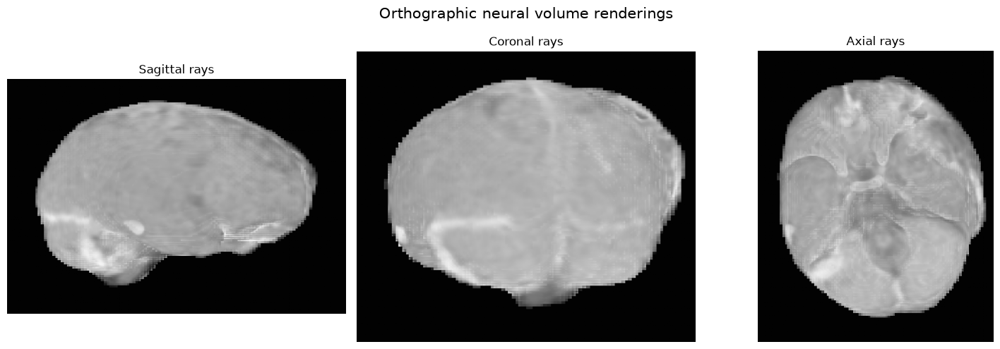

In [16]:
def ray_composite(volume_hu: np.ndarray, region_mask: np.ndarray, axis: int) -> np.ndarray:
    # Soft-tissue colour and opacity transfer function.
    hu = np.moveaxis(volume_hu, axis, -1)
    mask = np.moveaxis(region_mask, axis, -1)
    intensity = np.clip((hu + 20.0) / 90.0, 0.0, 1.0)
    alpha = np.where(mask, 0.035 + 0.055 * intensity, 0.0).astype(np.float32)
    transmittance = np.cumprod(1.0 - alpha + 1e-7, axis=-1)
    transmittance_before = np.concatenate((np.ones_like(transmittance[..., :1]), transmittance[..., :-1]), axis=-1)
    weights = alpha * transmittance_before
    grey = 0.10 + 0.90 * intensity
    rendered = np.sum(weights * grey, axis=-1)
    rendered += transmittance[..., -1] * 0.01
    return np.clip(rendered, 0.0, 1.0)


views = {
    "Sagittal rays": ray_composite(pred_soft_hu, brain, axis=0),
    "Coronal rays": ray_composite(pred_soft_hu, brain, axis=1),
    "Axial rays": ray_composite(pred_soft_hu, brain, axis=2),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, (title, rendered) in zip(axes, views.items()):
    axis.imshow(np.rot90(rendered), cmap="gray", vmin=0, vmax=1)
    axis.set_title(title)
    axis.axis("off")
plt.suptitle("Orthographic neural volume renderings", fontsize=15)
plt.tight_layout()
ray_render_path = FIGURE_DIR / "neural_ray_composited_views.png"
plt.savefig(ray_render_path, dpi=180, bbox_inches="tight")
plt.show()

## 6. Save a reproducibility summary

The reported fidelity applies to this one anonymized scan and the stated held-out planes. It does not establish diagnostic performance. A clinical study would require multiple patients, expert annotations and an external evaluation protocol.

In [17]:
raw_crop_bytes = int(ct.nbytes)
model_bytes = int((MODEL_DIR / "CASE_001_dual_window_siren.pt").stat().st_size)
summary = {
    "case": "CASE_001",
    "method": "patient-specific dual-window SIREN implicit neural representation",
    "source_ct": str(CT_PATH),
    "brain_mask": str(BRAIN_MASK_PATH),
    "skull_mask": str(SKULL_MASK_PATH),
    "original_shape": list(ct_full.shape),
    "working_shape": list(ct.shape),
    "downsample": DOWNSAMPLE,
    "held_out_every": HELD_OUT_EVERY,
    "held_out_z_indices": held_z.tolist(),
    "training_steps": TRAIN_STEPS,
    "batch_size": BATCH_SIZE,
    "trainable_parameters": parameter_count,
    "training_seconds": training_seconds,
    "inference_seconds": inference_seconds,
    "raw_working_crop_bytes_float32": raw_crop_bytes,
    "checkpoint_bytes": model_bytes,
    "raw_to_checkpoint_ratio": raw_crop_bytes / model_bytes,
    "metrics": metrics_df.to_dict(orient="records"),
    "outputs": {
        "checkpoint": str(MODEL_DIR / "CASE_001_dual_window_siren.pt"),
        "neural_nifti": str(neural_nifti_path),
        "metrics_csv": str(OUTPUT_DIR / "held_out_metrics.csv"),
        "slice_comparison": str(comparison_path),
        "training_curve": str(training_curve_path),
        "ray_composited_views": str(ray_render_path),
        "interactive_cutaway": str(cutaway_html),
        "skull_and_brain_3d": str(combined_anatomy_html),
        "skull_only_3d": str(skull_only_html),
        "brain_only_3d": str(brain_only_html),
        "interactive_volume": str(volume_html),
    },
    "interpretation_note": "Low-HU internal rendering is visualization-only and is not a clinical segmentation or diagnosis.",
}
summary_path = OUTPUT_DIR / "neural_rendering_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print(json.dumps({
    "training_minutes": round(training_seconds / 60.0, 2),
    "inference_seconds": round(inference_seconds, 2),
    "parameters": parameter_count,
    "raw_to_checkpoint_ratio": round(raw_crop_bytes / model_bytes, 2),
    "summary": str(summary_path),
}, indent=2))

{
  "training_minutes": 0.29,
  "inference_seconds": 1.41,
  "parameters": 66818,
  "raw_to_checkpoint_ratio": 272.86,
  "summary": "F:\\csstdy\\outputs\\11_neural_ct_rendering\\neural_rendering_summary.json"
}


## 7. Verification of Intracranial Low-HU Regions

This section independently verifies intracranial low-HU regions with the **original NIfTI CT as primary evidence**, the TotalSegmentator brain mask as an anatomical constraint, and the saved neural reconstruction only as a secondary consistency comparison.

This is research/image characterization rather than diagnosis. The terms *low-HU region*, *CSF-like intensity*, *ventricular/CSF candidate*, *central intracranial low-HU component*, and *hyperdense-material candidate* are descriptive. Definitive anatomical or pathological interpretation requires expert radiological review.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display
from scipy import ndimage as ndi

v7_root = Path(globals().get("PROJECT_ROOT", r"F:\csstdy"))
v7_output_dir = v7_root / "outputs" / "11_neural_ct_rendering"
v7_dir = v7_output_dir / "low_hu_verification"
v7_ct_path = v7_root / "outputs" / "09_totalsegmentator_dl_skull_brain" / "input" / "CASE_001_brain_kernel_ct.nii.gz"
v7_brain_path = v7_root / "outputs" / "09_totalsegmentator_dl_skull_brain" / "segmentations" / "brain.nii.gz"
v7_skull_path = v7_root / "outputs" / "09_totalsegmentator_dl_skull_brain" / "segmentations" / "skull.nii.gz"
v7_neural_path = v7_output_dir / "volumes" / "CASE_001_neural_ct_windows.npz"

for v7_path in (v7_dir, v7_ct_path, v7_brain_path, v7_skull_path, v7_neural_path):
    if not v7_path.exists():
        raise FileNotFoundError(v7_path)

# Independent copies: none of the original notebook arrays is changed in place.
v7_ct_img = nib.load(str(v7_ct_path))
v7_brain_img = nib.load(str(v7_brain_path))
v7_ct_full = np.asarray(v7_ct_img.dataobj, dtype=np.float32).copy()
v7_brain_full = (np.asarray(v7_brain_img.dataobj) > 0).copy()
with np.load(v7_neural_path) as v7_npz:
    v7_pred_soft_hu = np.asarray(v7_npz["soft_hu"], dtype=np.float32).copy()
    v7_saved_brain = (np.asarray(v7_npz["brain_mask"]) > 0).copy()
    v7_crop_affine = np.asarray(v7_npz["affine"], dtype=np.float64).copy()

v7_index_map = np.linalg.inv(v7_ct_img.affine) @ v7_crop_affine
if not np.allclose(v7_index_map[:3, :3], np.eye(3), atol=1e-4):
    raise ValueError("Neural volume is not a unit-step crop of the original CT grid.")
v7_offset = np.rint(v7_index_map[:3, 3]).astype(int)
v7_slices = tuple(slice(int(a), int(a + n)) for a, n in zip(v7_offset, v7_pred_soft_hu.shape))
v7_ct = v7_ct_full[v7_slices].copy()
v7_brain = v7_brain_full[v7_slices].copy()
if v7_ct.shape != v7_pred_soft_hu.shape or not np.array_equal(v7_brain, v7_saved_brain):
    raise ValueError("Original CT, TotalSegmentator brain mask, and neural archive are not aligned.")

v7_axcodes = nib.aff2axcodes(v7_crop_affine)
v7_spacing = np.linalg.norm(v7_crop_affine[:3, :3], axis=0)
v7_voxel_volume = float(abs(np.linalg.det(v7_crop_affine[:3, :3])))
v7_lr_axis = next(i for i, c in enumerate(v7_axcodes) if c in ("L", "R"))
v7_ap_axis = next(i for i, c in enumerate(v7_axcodes) if c in ("A", "P"))
v7_si_axis = next(i for i, c in enumerate(v7_axcodes) if c in ("S", "I"))
v7_conn26 = ndi.generate_binary_structure(3, 3)
v7_inner_brain = ndi.binary_erosion(
    v7_brain, structure=ndi.generate_binary_structure(3, 1), iterations=3
)
v7_native_low = v7_inner_brain & (v7_ct >= 0.0) & (v7_ct <= 20.0)
v7_neural_low = v7_inner_brain & (v7_pred_soft_hu >= 0.0) & (v7_pred_soft_hu <= 20.0)
v7_labels, v7_component_count = ndi.label(v7_native_low, structure=v7_conn26)
v7_boundary_distance = ndi.distance_transform_edt(v7_brain, sampling=tuple(v7_spacing))

print("Section 7 inputs loaded without executing any earlier notebook cell.")
print(f"Original CT crop: {v7_ct.shape}; orientation: {v7_axcodes}")
print(f"Voxel volume: {v7_voxel_volume:.4f} mm^3")
print("Evidence hierarchy: original CT → TotalSegmentator brain constraint → neural consistency check.")

Section 7 inputs loaded without executing any earlier notebook cell.
Original CT crop: (260, 322, 223); orientation: ('L', 'A', 'S')
Voxel volume: 0.2316 mm^3
Evidence hierarchy: original CT → TotalSegmentator brain constraint → neural consistency check.


### 7.1 Original CT intensity analysis

The statistics use true original CT values inside the TotalSegmentator brain mask. The displayed histogram is restricted to −20 to 100 HU for readability, while the calculations retain all values. The overlapping −5–15, 0–20, and 0–25 HU bands are a sensitivity analysis rather than diagnostic thresholds.

,measurement,value
0,voxel_count,4.975324e+06
1,minimum_hu,-1.021000e+03
2,maximum_hu,1.328000e+03
3,mean_hu,3.669827e+01
4,median_hu,3.700000e+01
5,standard_deviation_hu,1.977477e+01
6,percentile_1_hu,9.000000e+00
7,percentile_5_hu,1.800000e+01
8,percentile_10_hu,2.500000e+01
9,percentile_25_hu,3.200000e+01


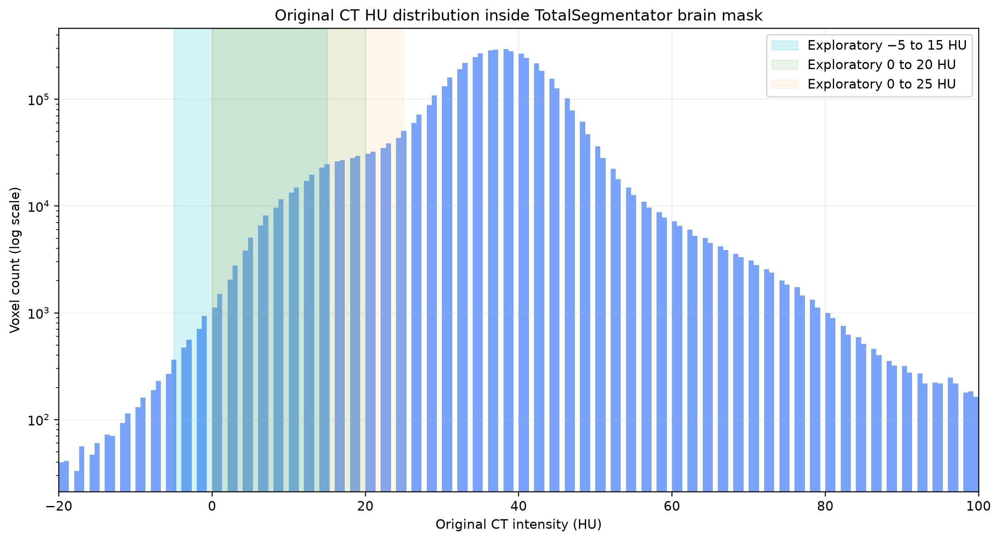

In [2]:
v7_brain_hu = v7_ct[v7_brain].astype(np.float64)
v7_ps = [1, 5, 10, 25, 50, 75, 90, 95, 99]
v7_stats = {
    "voxel_count": int(v7_brain_hu.size),
    "minimum_hu": float(v7_brain_hu.min()),
    "maximum_hu": float(v7_brain_hu.max()),
    "mean_hu": float(v7_brain_hu.mean()),
    "median_hu": float(np.median(v7_brain_hu)),
    "standard_deviation_hu": float(v7_brain_hu.std()),
}
v7_stats.update({
    f"percentile_{p}_hu": float(x)
    for p, x in zip(v7_ps, np.percentile(v7_brain_hu, v7_ps))
})
display(pd.DataFrame({"measurement": v7_stats.keys(), "value": v7_stats.values()}))
display(Image(filename=str(v7_dir / "original_brain_hu_histogram.png")))

### 7.2 Multi-threshold low-HU sensitivity analysis

Candidates are calculated from the original CT after three-voxel brain-mask erosion. Counts before filtering are retained. A 10 mm³ minimum component size was used only for conservative visualization; 0–20 HU is the nominal band.

In [3]:
v7_thresholds = {"A: -5 to 15 HU": (-5.0, 15.0), "B: 0 to 20 HU": (0.0, 20.0), "C: 0 to 25 HU": (0.0, 25.0)}
v7_min_voxels = max(1, int(np.ceil(10.0 / v7_voxel_volume)))
v7_live_rows = []
for name, (lo, hi) in v7_thresholds.items():
    mask = v7_inner_brain & (v7_ct >= lo) & (v7_ct <= hi)
    labels, before = ndi.label(mask, structure=v7_conn26)
    sizes = np.bincount(labels.ravel())
    after = int(np.sum(sizes[1:] >= v7_min_voxels))
    v7_live_rows.append({
        "threshold": name, "lower_hu": lo, "upper_hu": hi,
        "candidate_voxels": int(mask.sum()),
        "candidate_volume_mm3": float(mask.sum() * v7_voxel_volume),
        "percentage_of_inner_brain": float(100 * mask.sum() / max(v7_inner_brain.sum(), 1)),
        "components_before_filtering": int(before),
        "components_after_filtering": after,
    })
v7_live_sensitivity = pd.DataFrame(v7_live_rows)
v7_saved_sensitivity = pd.read_csv(v7_dir / "low_hu_threshold_sensitivity.csv")
assert np.array_equal(v7_live_sensitivity["candidate_voxels"], v7_saved_sensitivity["candidate_voxels"])
display(v7_saved_sensitivity)
print("Nominal visualization threshold: 0–20 HU.")

,threshold,lower_hu,upper_hu,candidate_voxels,candidate_volume_mm3,percentage_of_inner_brain,components_before_filtering,components_after_filtering,visualization_min_component_mm3
0,A: -5 to 15 HU,-5.0,15.0,121049,28039.823990,2.681000,1292,82,10.0
1,B: 0 to 20 HU,0.0,20.0,225958,52340.973895,5.004530,2138,136,10.0
2,C: 0 to 25 HU,0.0,25.0,388394,89967.694063,8.602172,5994,162,10.0


Nominal visualization threshold: 0–20 HU.


### 7.3 Connected-component analysis

The nominal native-CT mask uses 26-connectivity. All original components are counted before filtering. The saved component table records components of at least 10 mm³ with physical volume, voxel/world centroid, bounding box, slice span, HU statistics, boundary distance, and normalized centrality. Major visualization components use at least 50 mm³ and at least three consecutive slices.

In [4]:
v7_components = pd.read_csv(v7_dir / "native_low_hu_components.csv")
v7_major = v7_components[
    (v7_components["volume_mm3"] >= 50.0)
    & (v7_components["longest_consecutive_slice_run"] >= 3)
].copy()
if v7_major.empty:
    v7_major = v7_components.nlargest(1, "volume_mm3").copy()
v7_major_ids = v7_major["component_id"].astype(int).to_numpy()
v7_major_mask = np.isin(v7_labels, v7_major_ids)
print(f"Components before filtering: {v7_component_count}")
print(f"Recorded components (>=10 mm³): {len(v7_components)}")
print(f"Major persistent components: {len(v7_major)}")
display(v7_components)

Components before filtering: 2138
Recorded components (>=10 mm³): 136
Major persistent components: 47


,component_id,number_of_voxels,volume_mm3,centroid_voxel_x,centroid_voxel_y,centroid_voxel_z,centroid_world_x_mm,centroid_world_y_mm,centroid_world_z_mm,bounding_box_voxel,...,longest_consecutive_slice_run,minimum_hu,maximum_hu,mean_hu,median_hu,hu_standard_deviation,median_distance_from_brain_boundary_mm,maximum_distance_from_brain_boundary_mm,normalized_centrality,fraction_inside_brain_mask
0,8,132712,30741.444550,126.454058,156.759020,100.100496,20.588147,139.720168,-527.662604,"[27:230, 68:236, 28:147]",...,119,0.0,20.0,12.806340,13.0,4.637396,23.891169,47.757596,0.484242,1.0
1,1589,14147,3277.015010,214.273768,224.344879,88.238213,-28.217312,177.280744,-536.559316,"[182:243, 186:257, 64:140]",...,76,0.0,20.0,15.673641,17.0,3.997916,3.890223,10.400640,0.078850,1.0
2,311,10963,2539.472366,102.369060,225.443583,158.362948,33.973291,177.891344,-483.965765,"[73:132, 135:281, 102:192]",...,90,0.0,20.0,15.412570,16.0,3.760539,7.063881,31.215921,0.143175,1.0
3,1233,9490,2198.266237,202.720864,193.325606,127.567018,-21.796831,160.041905,-507.062713,"[159:243, 143:229, 102:163]",...,61,0.0,20.0,15.451212,16.0,3.794454,19.805624,31.023205,0.401434,1.0
4,957,7340,1700.239639,162.071390,275.106812,129.302452,0.793955,205.491489,-505.761137,"[138:193, 247:292, 96:169]",...,73,0.0,20.0,14.720981,15.0,3.980993,3.143775,9.553844,0.063720,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
131,362,45,10.423813,82.333333,160.066667,71.844444,45.108067,141.558380,-548.854643,"[79:86, 157:164, 70:75]",...,5,13.0,20.0,17.800000,18.0,2.072036,8.720810,9.569833,0.176759,1.0
132,1210,45,10.423813,163.022222,130.200000,191.288889,0.265534,124.960097,-459.271309,"[158:166, 128:135, 189:194]",...,5,12.0,20.0,17.577778,18.0,1.994313,3.000000,4.415997,0.060806,1.0
133,699,45,10.423813,116.422222,267.244444,93.333333,26.163301,201.122009,-532.737976,"[113:119, 263:272, 90:97]",...,7,16.0,20.0,19.377778,20.0,0.925896,7.279320,9.739441,0.147542,1.0
134,16,44,10.192172,31.818182,131.295455,128.818182,73.181665,125.568891,-506.124340,"[30:36, 128:135, 126:131]",...,5,13.0,20.0,18.045455,19.0,1.718278,3.334476,4.889026,0.067585,1.0


### 7.4 Location and centrality check

Euclidean boundary distance uses the NIfTI-derived physical spacing. Centrality, separation from the outer boundary, containment in the brain mask, and multi-slice continuity are evaluated together. Boundary-adjacent components are not automatically called ventricular candidates.

In [5]:
v7_location_columns = [
    "component_id", "fraction_inside_brain_mask",
    "median_distance_from_brain_boundary_mm",
    "maximum_distance_from_brain_boundary_mm",
    "normalized_centrality", "number_of_axial_slices_occupied",
    "longest_consecutive_slice_run",
]
display(v7_major[v7_location_columns])

,component_id,fraction_inside_brain_mask,median_distance_from_brain_boundary_mm,maximum_distance_from_brain_boundary_mm,normalized_centrality,number_of_axial_slices_occupied,longest_consecutive_slice_run
0,8,1.0,23.891169,47.757596,0.484242,119,119
1,1589,1.0,3.890223,10.400640,0.078850,76,76
2,311,1.0,7.063881,31.215921,0.143175,90,90
3,1233,1.0,19.805624,31.023205,0.401434,61,61
4,957,1.0,3.143775,9.553844,0.063720,73,73
5,1070,1.0,14.342126,24.966177,0.290696,29,29
6,1130,1.0,3.618383,14.771470,0.073340,27,27
7,1464,1.0,22.420017,27.638193,0.454424,34,34
8,1693,1.0,4.279064,18.751563,0.086731,26,26
9,292,1.0,4.415997,11.462003,0.089506,31,31


### 7.5 Left–right symmetry check

The left–right axis is determined from nib.aff2axcodes(crop_affine), not assumed. Reflection across the estimated midsagittal plane supplies an anatomical-consistency feature only; symmetry does not prove ventricular anatomy.

In [6]:
def v7_overlap(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    inter = int((a & b).sum())
    union = int((a | b).sum())
    return {
        "dice": float(2 * inter / max(int(a.sum() + b.sum()), 1)),
        "jaccard": float(inter / max(union, 1)),
        "sensitivity": float(inter / max(int(a.sum()), 1)),
        "precision": float(inter / max(int(b.sum()), 1)),
    }

v7_lr_extent = np.where(np.any(v7_brain, axis=tuple(i for i in range(3) if i != v7_lr_axis)))[0]
v7_mid = 0.5 * (int(v7_lr_extent.min()) + int(v7_lr_extent.max()))
v7_coords = np.argwhere(v7_native_low)
v7_reflected_coords = v7_coords.copy()
v7_reflected_coords[:, v7_lr_axis] = np.rint(2 * v7_mid - v7_coords[:, v7_lr_axis]).astype(int)
v7_valid = np.all((v7_reflected_coords >= 0) & (v7_reflected_coords < np.array(v7_native_low.shape)), axis=1)
v7_reflected = np.zeros_like(v7_native_low)
v7_reflected[tuple(v7_reflected_coords[v7_valid].T)] = True
v7_reflected &= v7_inner_brain
v7_symmetry = v7_overlap(v7_native_low, v7_reflected)

v7_grid = np.indices(v7_native_low.shape, sparse=True)[v7_lr_axis]
v7_low_side, v7_high_side = v7_grid < v7_mid, v7_grid > v7_mid
if v7_axcodes[v7_lr_axis] == "R":
    v7_left_side, v7_right_side = v7_low_side, v7_high_side
else:
    v7_left_side, v7_right_side = v7_high_side, v7_low_side
v7_left_volume = float((v7_native_low & v7_left_side).sum() * v7_voxel_volume)
v7_right_volume = float((v7_native_low & v7_right_side).sum() * v7_voxel_volume)
v7_symmetry_row = {
    "axis_codes": str(v7_axcodes), "left_right_axis": v7_lr_axis,
    "reflection_dice": v7_symmetry["dice"], "reflection_jaccard": v7_symmetry["jaccard"],
    "left_candidate_volume_mm3": v7_left_volume,
    "right_candidate_volume_mm3": v7_right_volume,
    "left_right_volume_ratio": v7_left_volume / v7_right_volume if v7_right_volume else np.nan,
}
display(pd.DataFrame([v7_symmetry_row]))

,axis_codes,left_right_axis,reflection_dice,reflection_jaccard,left_candidate_volume_mm3,right_candidate_volume_mm3,left_right_volume_ratio
0,"('L', 'A', 'S')",0,0.129146,0.06903,24809.831956,27155.653049,0.913616


### 7.6 Adjacent-slice persistence

Persistence is measured along the anatomically identified superior–inferior axis. persistent_3d is true only for components occupying at least three consecutive axial slices. Persistence by itself is not diagnostic.

In [7]:
v7_persistence = v7_major[[
    "component_id", "first_axial_slice", "last_axial_slice",
    "number_of_axial_slices_occupied", "longest_consecutive_slice_run"
]].copy()
v7_persistence["persistent_3d"] = v7_persistence["longest_consecutive_slice_run"] >= 3
display(v7_persistence)

,component_id,first_axial_slice,last_axial_slice,number_of_axial_slices_occupied,longest_consecutive_slice_run,persistent_3d
0,8,28,146,119,119,True
1,1589,64,139,76,76,True
2,311,102,191,90,90,True
3,1233,102,162,61,61,True
4,957,96,168,73,73,True
5,1070,110,138,29,29,True
6,1130,165,191,27,27,True
7,1464,82,115,34,34,True
8,1693,155,180,26,26,True
9,292,73,103,31,31,True


### 7.7 Original CT versus neural reconstruction

The same 0–20 HU mask is constructed independently from the original CT and the neural reconstruction. The original candidate is the reference for Dice, Jaccard, sensitivity, precision, volume difference, and HU errors; the neural result is not ground truth.

In [8]:
v7_abs_error = np.abs(v7_ct.astype(np.float64) - v7_pred_soft_hu.astype(np.float64))
v7_native_neural = v7_overlap(v7_native_low, v7_neural_low)
v7_low_errors = v7_abs_error[v7_native_low]
v7_comparison = pd.read_csv(v7_dir / "native_vs_neural_low_hu_comparison.csv")
assert np.isclose(v7_native_neural["dice"], v7_comparison.iloc[0]["Dice"])
display(v7_comparison)
print(f"Native candidate volume: {v7_native_low.sum() * v7_voxel_volume:.2f} mm³")
print(f"Neural candidate volume: {v7_neural_low.sum() * v7_voxel_volume:.2f} mm³")

,Region,Dice,Jaccard,Sensitivity,Precision,MAE HU,Median AE HU,95th percentile AE HU,native_candidate_volume_mm3,neural_candidate_volume_mm3,candidate_volume_difference_mm3
0,Native 0–20 HU candidate,0.570771,0.399355,0.427761,0.857427,7.994066,7.269337,17.726507,52340.973895,26112.345238,-26228.628657
1,Whole TotalSegmentator brain,0.570771,0.399355,0.427761,0.857427,4.982072,3.613186,12.235260,52340.973895,26112.345238,-26228.628657


Native candidate volume: 52340.97 mm³
Neural candidate volume: 26112.35 mm³


### 7.8 Multiplanar visual verification

Representative axial, coronal, and sagittal planes were selected from the largest major original-CT component. Each panel explicitly distinguishes the original CT, native low-HU contour, neural reconstruction, and absolute HU difference.

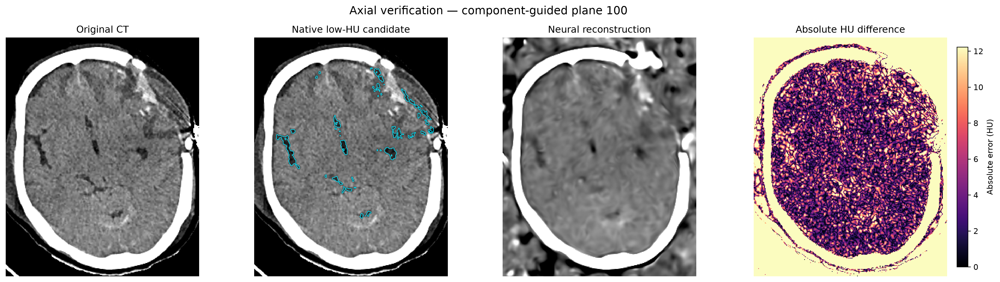

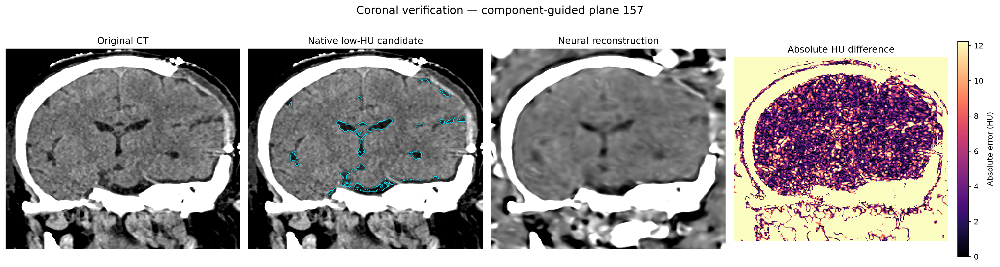

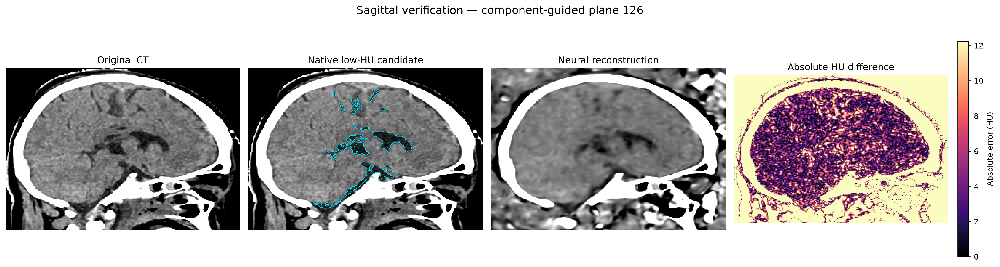

In [9]:
for v7_name in (
    "native_low_hu_axial_verification.png",
    "native_low_hu_coronal_verification.png",
    "native_low_hu_sagittal_verification.png",
):
    display(Image(filename=str(v7_dir / v7_name)))

### 7.9 3D low-HU candidate visualization

The separate interactive Plotly figure combines a translucent TotalSegmentator brain surface with original-CT-derived low-HU components in patient/world millimetres. It does not use the SIREN-derived internal-low mask and does not replace any earlier 3D output.

In [10]:
v7_3d_path = v7_dir / "CASE_001_native_low_hu_3d_verification.html"
display(HTML(
    f'<p><b>Interactive 3D:</b> <a href="{v7_3d_path.as_posix()}" '
    f'target="_blank">{v7_3d_path.name}</a></p>'
))
print("Title: Original CT — intracranial low-HU candidate verification")
print(v7_3d_path)

Title: Original CT — intracranial low-HU candidate verification
F:\csstdy\outputs\11_neural_ct_rendering\low_hu_verification\CASE_001_native_low_hu_3d_verification.html


### 7.10 Hyperdense-material check inside or around low-HU spaces

The structured annotation is report-level information, not a voxel-level mask or ground truth. Exploratory 35–80 HU and 40–100 HU ranges identify only hyperdense-material candidates within or immediately adjacent to major low-HU components. CT intensity alone is insufficient for diagnosis.

In [11]:
v7_annotation_matches = list(v7_root.rglob("CASE_001_structured_annotations.csv"))
v7_annotation_path = v7_annotation_matches[0] if v7_annotation_matches else None
v7_ivh_available = False
if v7_annotation_path:
    v7_annotations = pd.read_csv(v7_annotation_path)
    v7_text = v7_annotations.astype(str).agg(" ".join, axis=1)
    v7_ivh_rows = v7_annotations[
        v7_text.str.contains(r"\bintraventricular\b|\bIVH\b", case=False, regex=True, na=False)
    ]
    v7_ivh_available = not v7_ivh_rows.empty
    if v7_ivh_available:
        v7_cols = [c for c in ("finding", "region", "report_status", "certainty") if c in v7_ivh_rows]
        display(v7_ivh_rows[v7_cols])
else:
    print("Structured annotation CSV unavailable; cross-check skipped safely.")

v7_hyperdensity = pd.read_csv(v7_dir / "ventricular_region_hyperdensity_check.csv")
display(v7_hyperdensity)
print("These are hyperdense-material candidates only.")
print("CT intensity alone is insufficient for diagnosis, and the structured annotation is not a voxel-level ground truth.")

,finding,region,report_status,certainty
3,Intraventricular hemorrhage (IVH),Bilateral lateral ventricular occipital horns,Likely,Reported as likely


,exploratory_range,lower_hu,upper_hu,hyperdense_candidate_voxels,volume_mm3,overlap_with_low_hu_voxels,within_3mm_but_not_overlapping_voxels,representative_axial_slices
0,35 to 80 HU,35.0,80.0,529682,122695.685636,0,529682,"[126, 127, 122]"
1,40 to 100 HU,40.0,100.0,308692,71505.500640,0,308692,"[85, 84, 181]"


These are hyperdense-material candidates only.
CT intensity alone is insufficient for diagnosis, and the structured annotation is not a voxel-level ground truth.


### 7.11 Original CT slice montage

Nine consecutive original CT slices through the largest central low-HU component show the native anatomy with thin low-HU contours, allowing direct inspection of adjacent-slice persistence.

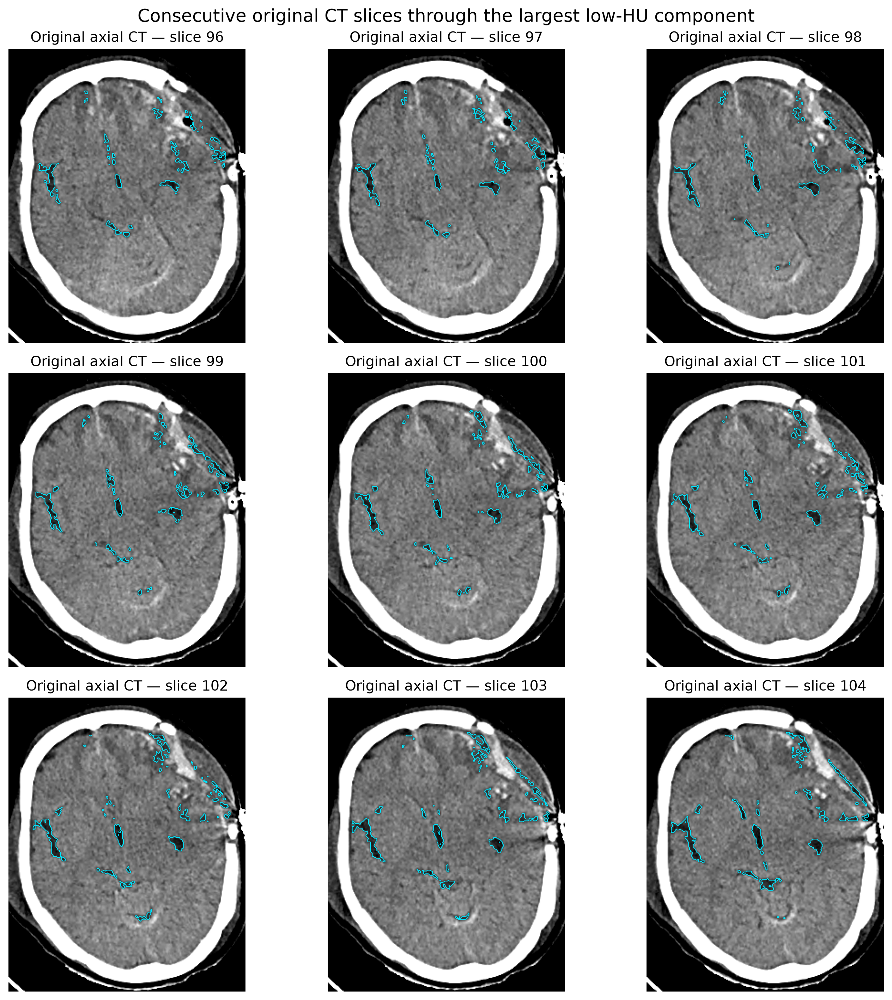

In [12]:
display(Image(filename=str(v7_dir / "native_low_hu_consecutive_slice_montage.png")))

### 7.12 Quantitative verification scorecard

The scorecard uses conservative descriptions only: central persistent CSF-like low-HU candidate, peripheral low-HU candidate, small/isolated low-HU candidate, and requires radiological interpretation.

In [13]:
v7_scorecard = pd.read_csv(v7_dir / "low_hu_verification_scorecard.csv")
display(v7_scorecard)

,component_id,volume_mm3,mean_hu,median_hu,slice_span,longest_consecutive_run,median_boundary_distance_mm,centrality,left_right_symmetry_support,native_neural_dice,classification_note
0,8,30741.444550,12.806340,13.0,119,119,23.891169,0.484242,0.147359,0.625847,central persistent CSF-like low-HU candidate; ...
1,1589,3277.015010,15.673641,17.0,76,76,3.890223,0.078850,0.002501,0.098853,peripheral low-HU candidate; requires radiolog...
2,311,2539.472366,15.412570,16.0,90,90,7.063881,0.143175,0.004311,0.039097,small/isolated low-HU candidate; requires radi...
3,1233,2198.266237,15.451212,16.0,61,61,19.805624,0.401434,0.000980,0.037572,central persistent CSF-like low-HU candidate; ...
4,957,1700.239639,14.720981,15.0,73,73,3.143775,0.063720,0.003378,0.050738,peripheral low-HU candidate; requires radiolog...
5,1070,1378.491293,17.677029,18.0,29,29,14.342126,0.290696,0.001915,0.024655,central persistent CSF-like low-HU candidate; ...
6,1130,687.508345,16.224057,17.0,27,27,3.618383,0.073340,0.001418,0.013968,peripheral low-HU candidate; requires radiolog...
7,1464,398.884558,18.069686,18.0,34,34,22.420017,0.454424,0.000000,0.001678,central persistent CSF-like low-HU candidate; ...
8,1693,386.144343,16.531494,17.0,26,26,4.279064,0.086731,0.000000,0.004860,peripheral low-HU candidate; requires radiolog...
9,292,369.697883,17.075815,18.0,31,31,4.415997,0.089506,0.000571,0.003779,peripheral low-HU candidate; requires radiolog...


### 7.13 Final verification figure

This presentation figure summarizes original-CT visibility, native contours, neural consistency, component mapping, HU correspondence, and the low-HU band. It is not diagnostic validation.

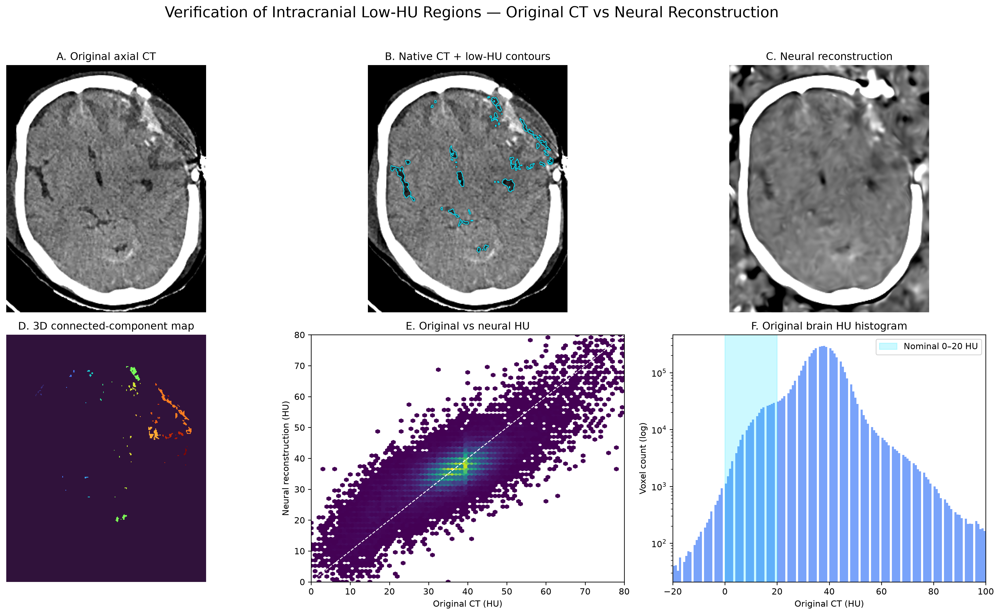

In [14]:
display(Image(filename=str(v7_dir / "low_hu_verification_summary.png")))

### 7.14 Machine-readable summary

The JSON record includes threshold sensitivity, major components, symmetry, slice persistence, native-versus-neural comparison, annotation cross-check, exploratory hyperdensity analysis, and explicit limitations.

In [15]:
v7_summary_path = v7_dir / "low_hu_verification_summary.json"
v7_summary = json.loads(v7_summary_path.read_text(encoding="utf-8"))
v7_largest = v7_major.sort_values("volume_mm3", ascending=False).iloc[0]
v7_persistent_count = int(v7_persistence["persistent_3d"].sum())

print("Native CT analysis completed.")
print(f"HU range of major low-density components: {v7_major['minimum_hu'].min():.2f} to {v7_major['maximum_hu'].max():.2f} HU")
print(f"Number of major persistent components: {v7_persistent_count}")
print(f"Largest component volume: {v7_largest['volume_mm3']:.2f} mm^3")
print(f"Left-right reflection Dice: {v7_symmetry['dice']:.4f}")
print(f"Native-vs-neural low-HU Dice: {v7_native_neural['dice']:.4f}")
print(f"Native-vs-neural HU MAE in native low-HU candidate: {v7_low_errors.mean():.3f} HU")
print(f"Dark regions independently visible in original CT: {bool(v7_native_low.any())}")
print(f"Persistence through adjacent slices: {bool(v7_persistent_count > 0)}")
print(f"Report-level IVH information available: {v7_ivh_available}")
print(
    "The dominant dark structures are independently present in the original CT, show CSF-like "
    "attenuation, occupy central intracranial locations, and persist across neighbouring slices. "
    "These properties are compatible with ventricular/CSF-containing spaces. The analysis is "
    "anatomical and quantitative rather than diagnostic."
)
print(f"Machine-readable summary: {v7_summary_path}")
print("Section 7 appended successfully; all previous notebook cells and outputs preserved.")

Native CT analysis completed.
HU range of major low-density components: 0.00 to 20.00 HU
Number of major persistent components: 47
Largest component volume: 30741.44 mm^3
Left-right reflection Dice: 0.1291
Native-vs-neural low-HU Dice: 0.5708
Native-vs-neural HU MAE in native low-HU candidate: 7.994 HU
Dark regions independently visible in original CT: True
Persistence through adjacent slices: True
Report-level IVH information available: True
The dominant dark structures are independently present in the original CT, show CSF-like attenuation, occupy central intracranial locations, and persist across neighbouring slices. These properties are compatible with ventricular/CSF-containing spaces. The analysis is anatomical and quantitative rather than diagnostic.
Machine-readable summary: F:\csstdy\outputs\11_neural_ct_rendering\low_hu_verification\low_hu_verification_summary.json
Section 7 appended successfully; all previous notebook cells and outputs preserved.


## 8. Anatomical Classification of the Intracranial Dark Spaces

This section addresses the anatomical question: **What are the dark intracranial spaces identified in Section 7?**

The analysis remains image-based anatomical classification rather than independent disease diagnosis. Evidence is ordered as follows: original CT anatomy and HU, spatial position, midsagittal relationship, boundary depth, 3D morphology and continuity, bilateral and multiplanar pattern, Section 7 measurements, report-level annotation, and finally the neural reconstruction as secondary confirmation.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import HTML, display
from scipy import ndimage as ndi
from skimage import measure

v8_root = Path(globals().get("PROJECT_ROOT", r"F:\csstdy"))
v8_output_root = v8_root / "outputs" / "11_neural_ct_rendering"
v8_section7_dir = v8_output_root / "low_hu_verification"
v8_dir = v8_output_root / "anatomical_classification"
if v8_dir.exists():
    raise FileExistsError(f"{v8_dir} already exists; refusing to overwrite a prior Section 8 analysis.")
v8_dir.mkdir(parents=True, exist_ok=False)

v8_ct_path = v8_root / "outputs" / "09_totalsegmentator_dl_skull_brain" / "input" / "CASE_001_brain_kernel_ct.nii.gz"
v8_brain_path = v8_root / "outputs" / "09_totalsegmentator_dl_skull_brain" / "segmentations" / "brain.nii.gz"
v8_neural_path = v8_output_root / "volumes" / "CASE_001_neural_ct_windows.npz"
for v8_path in (v8_ct_path, v8_brain_path, v8_neural_path, v8_section7_dir):
    if not v8_path.exists():
        raise FileNotFoundError(v8_path)

# Load new copies. No Section 1–7 variable or array is modified.
v8_ct_img = nib.load(str(v8_ct_path))
v8_brain_img = nib.load(str(v8_brain_path))
v8_ct_full = np.asarray(v8_ct_img.dataobj, dtype=np.float32).copy()
v8_brain_full = (np.asarray(v8_brain_img.dataobj) > 0).copy()
with np.load(v8_neural_path) as v8_npz:
    v8_pred_soft_hu = np.asarray(v8_npz["soft_hu"], dtype=np.float32).copy()
    v8_saved_brain = (np.asarray(v8_npz["brain_mask"]) > 0).copy()
    v8_crop_affine = np.asarray(v8_npz["affine"], dtype=np.float64).copy()

v8_index_map = np.linalg.inv(v8_ct_img.affine) @ v8_crop_affine
if not np.allclose(v8_index_map[:3, :3], np.eye(3), atol=1e-4):
    raise ValueError("The saved neural volume is not a unit-step crop of the original CT grid.")
v8_offset = np.rint(v8_index_map[:3, 3]).astype(int)
v8_crop_slices = tuple(
    slice(int(start), int(start + size))
    for start, size in zip(v8_offset, v8_pred_soft_hu.shape)
)
v8_ct = v8_ct_full[v8_crop_slices].copy()
v8_brain = v8_brain_full[v8_crop_slices].copy()
if v8_ct.shape != v8_pred_soft_hu.shape or not np.array_equal(v8_brain, v8_saved_brain):
    raise ValueError("Original CT, TotalSegmentator brain mask, and neural volume are not aligned.")

v8_axcodes = nib.aff2axcodes(v8_crop_affine)
v8_spacing = np.linalg.norm(v8_crop_affine[:3, :3], axis=0)
v8_voxel_volume = float(abs(np.linalg.det(v8_crop_affine[:3, :3])))
v8_lr_axis = next(i for i, c in enumerate(v8_axcodes) if c in ("L", "R"))
v8_ap_axis = next(i for i, c in enumerate(v8_axcodes) if c in ("A", "P"))
v8_si_axis = next(i for i, c in enumerate(v8_axcodes) if c in ("S", "I"))
v8_conn26 = ndi.generate_binary_structure(3, 3)
v8_inner_brain = ndi.binary_erosion(
    v8_brain, structure=ndi.generate_binary_structure(3, 1), iterations=3
)
v8_native_low = v8_inner_brain & np.isfinite(v8_ct) & (v8_ct >= 0.0) & (v8_ct <= 20.0)
v8_boundary_distance = ndi.distance_transform_edt(v8_brain, sampling=tuple(v8_spacing))

v8_brain_coords = np.argwhere(v8_brain)
v8_bbox_min = v8_brain_coords.min(axis=0)
v8_bbox_max = v8_brain_coords.max(axis=0)
v8_bbox_span = np.maximum(v8_bbox_max - v8_bbox_min, 1)
v8_brain_mid = 0.5 * (v8_bbox_min + v8_bbox_max)
v8_grid = np.indices(v8_ct.shape, sparse=True)
v8_lr_mm = (v8_grid[v8_lr_axis] - v8_brain_mid[v8_lr_axis]) * v8_spacing[v8_lr_axis]
v8_ap_fraction = (v8_grid[v8_ap_axis] - v8_bbox_min[v8_ap_axis]) / v8_bbox_span[v8_ap_axis]
v8_si_fraction = (v8_grid[v8_si_axis] - v8_bbox_min[v8_si_axis]) / v8_bbox_span[v8_si_axis]

v8_section7_components = pd.read_csv(v8_section7_dir / "native_low_hu_components.csv")
v8_section7_comparison = pd.read_csv(v8_section7_dir / "native_vs_neural_low_hu_comparison.csv")
v8_section7_summary = json.loads(
    (v8_section7_dir / "low_hu_verification_summary.json").read_text(encoding="utf-8")
)

print("Section 8 source data loaded independently; SIREN training was not run.")
print(f"Original CT crop: {v8_ct.shape}; orientation: {v8_axcodes}")
print(f"Patient-space voxel sizes: {np.round(v8_spacing, 4)} mm")
print(f"New Section 8 outputs: {v8_dir}")

Section 8 source data loaded independently; SIREN training was not run.
Original CT crop: (260, 322, 223); orientation: ('L', 'A', 'S')
Patient-space voxel sizes: [0.5557 0.5557 0.75  ] mm
New Section 8 outputs: F:\csstdy\outputs\11_neural_ct_rendering\anatomical_classification


### 8.1–8.4 Primary question, evidence verification, and subdivision principle

Section 7 measurements are read and checked against a fresh original-CT nominal mask. A 26-connected component can join different CSF-containing or low-attenuation spaces through thin bridges, so the largest component is **not** classified wholesale as a single ventricle. Section 8 instead subdivides candidates by depth, midsagittal relationship, brain-relative position, morphology, continuity, and laterality.

In [2]:
v8_largest_s7 = v8_section7_components.sort_values("volume_mm3", ascending=False).iloc[0]
v8_nominal_s7 = next(
    row for row in v8_section7_summary["threshold_sensitivity_results"]
    if float(row["lower_hu"]) == 0.0 and float(row["upper_hu"]) == 20.0
)
v8_fresh_voxels = int(v8_native_low.sum())
if v8_fresh_voxels != int(v8_nominal_s7["candidate_voxels"]):
    raise AssertionError("Fresh original-CT low-HU mask does not reproduce Section 7 voxel count.")

v8_verified_results = pd.DataFrame([{
    "nominal_hu_range": "0–20 HU",
    "fresh_native_candidate_voxels": v8_fresh_voxels,
    "largest_section7_component_id": int(v8_largest_s7["component_id"]),
    "largest_component_volume_mm3": float(v8_largest_s7["volume_mm3"]),
    "largest_component_mean_hu": float(v8_largest_s7["mean_hu"]),
    "largest_component_median_hu": float(v8_largest_s7["median_hu"]),
    "largest_component_persistence_slices": int(v8_largest_s7["longest_consecutive_slice_run"]),
    "largest_component_median_boundary_distance_mm": float(
        v8_largest_s7["median_distance_from_brain_boundary_mm"]
    ),
    "largest_component_normalized_centrality": float(v8_largest_s7["normalized_centrality"]),
    "native_neural_low_hu_dice": float(v8_section7_comparison.iloc[0]["Dice"]),
    "native_neural_low_hu_mae": float(v8_section7_comparison.iloc[0]["MAE HU"]),
    "left_right_volume_ratio": float(v8_section7_summary["symmetry_statistics"]["left_right_volume_ratio"]),
}])
display(v8_verified_results)
print(
    "The largest 26-connected region is treated as a mixed parent candidate, "
    "not automatically as a single anatomical structure."
)

,nominal_hu_range,fresh_native_candidate_voxels,largest_section7_component_id,largest_component_volume_mm3,largest_component_mean_hu,largest_component_median_hu,largest_component_persistence_slices,largest_component_median_boundary_distance_mm,largest_component_normalized_centrality,native_neural_low_hu_dice,native_neural_low_hu_mae,left_right_volume_ratio
0,0–20 HU,225958,8,30741.44455,12.80634,13.0,119,23.891169,0.484242,0.570771,7.994066,0.913616


The largest 26-connected region is treated as a mixed parent candidate, not automatically as a single anatomical structure.


### 8.5 Deep versus peripheral CSF classification

Deep-candidate sensitivity is shown at boundary distances greater than 8, 10, and 12 mm. The nominal 10 mm criterion is chosen explicitly as a middle setting: it reduces surface-following partial-volume and sulcal regions while retaining a substantial deep candidate for anatomical subdivision. Peripheral candidates are those within 8 mm of the brain boundary; the 8–10 mm transition band remains uncertain.

In [3]:
v8_depth_rows = []
for v8_depth_mm in (8.0, 10.0, 12.0):
    v8_deep_test = v8_native_low & (v8_boundary_distance > v8_depth_mm)
    v8_labels_test, v8_count_test = ndi.label(v8_deep_test, structure=v8_conn26)
    v8_depth_rows.append({
        "deep_boundary_criterion_mm": f"> {v8_depth_mm:g}",
        "voxel_count": int(v8_deep_test.sum()),
        "volume_mm3": float(v8_deep_test.sum() * v8_voxel_volume),
        "percentage_of_nominal_low_hu": float(100 * v8_deep_test.sum() / max(v8_native_low.sum(), 1)),
        "connected_components": int(v8_count_test),
    })
v8_depth_sensitivity = pd.DataFrame(v8_depth_rows)
v8_depth_sensitivity_path = v8_dir / "deep_peripheral_boundary_sensitivity.csv"
v8_depth_sensitivity.to_csv(v8_depth_sensitivity_path, index=False)
display(v8_depth_sensitivity)

v8_nominal_depth_mm = 10.0
v8_deep_low_hu = v8_native_low & (v8_boundary_distance > v8_nominal_depth_mm)
v8_peripheral_low_hu = v8_native_low & (v8_boundary_distance <= 8.0)
v8_transition_low_hu = v8_native_low & (v8_boundary_distance > 8.0) & (v8_boundary_distance <= 10.0)
print("Nominal deep criterion: boundary distance > 10 mm.")
print(f"Deep volume: {v8_deep_low_hu.sum() * v8_voxel_volume:.2f} mm³")
print(f"Peripheral volume (<=8 mm): {v8_peripheral_low_hu.sum() * v8_voxel_volume:.2f} mm³")
print(f"Uncertain transition volume (8–10 mm): {v8_transition_low_hu.sum() * v8_voxel_volume:.2f} mm³")

,deep_boundary_criterion_mm,voxel_count,volume_mm3,percentage_of_nominal_low_hu,connected_components
0,> 8,130644,30262.412455,57.817825,1425
1,> 10,120419,27893.890615,53.292647,1225
2,> 12,111077,25729.907139,49.158251,1058


Nominal deep criterion: boundary distance > 10 mm.
Deep volume: 27893.89 mm³
Peripheral volume (<=8 mm): 22078.56 mm³
Uncertain transition volume (8–10 mm): 2368.52 mm³


### 8.6 Midsagittal-plane identification

The left–right axis and direction are derived from the crop affine. The midsagittal plane is estimated from the midpoint of the TotalSegmentator brain extent along that anatomical axis and displayed on component-guided axial slices.

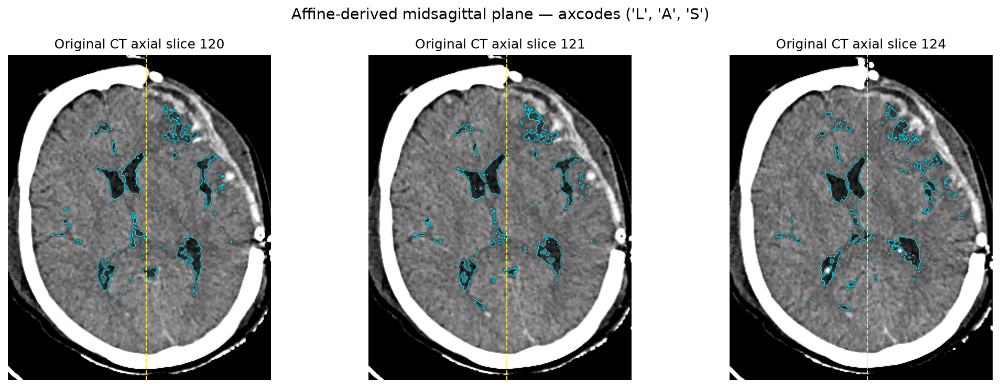

Left-right array axis: 0; increasing direction: L
Estimated midsagittal voxel coordinate: 136.00
Brain-centre world coordinate: [  15.28  141.8  -517.61] mm


In [4]:
v8_lr_code = v8_axcodes[v8_lr_axis]
v8_mid_index = float(v8_brain_mid[v8_lr_axis])
v8_mid_world = nib.affines.apply_affine(
    v8_crop_affine,
    np.array([v8_brain_mid[0], v8_brain_mid[1], v8_brain_mid[2]], dtype=float)
)

v8_axial_counts = np.sum(v8_deep_low_hu, axis=tuple(i for i in range(3) if i != v8_si_axis))
v8_midcheck_slices = np.argsort(v8_axial_counts)[-3:]

def v8_plane(array, axis, index):
    return np.rot90(np.take(array, int(index), axis=int(axis)))

v8_fig, v8_axes = plt.subplots(1, 3, figsize=(14, 5), dpi=150)
for v8_ax, v8_z in zip(v8_axes, np.sort(v8_midcheck_slices)):
    v8_ax.imshow(v8_plane(v8_ct, v8_si_axis, v8_z), cmap="gray", vmin=0, vmax=80)
    v8_mask_plane = v8_plane(v8_deep_low_hu, v8_si_axis, v8_z)
    if v8_mask_plane.any():
        v8_ax.contour(v8_mask_plane.astype(float), levels=[0.5], colors=["#00e5ff"], linewidths=0.6)
    # In an axial slice rotated from (LR, AP), the LR voxel coordinate is the horizontal coordinate.
    v8_ax.axvline(v8_mid_index, color="#ffeb3b", linestyle="--", linewidth=1.0)
    v8_ax.set_title(f"Original CT axial slice {int(v8_z)}")
    v8_ax.axis("off")
v8_fig.suptitle(f"Affine-derived midsagittal plane — axcodes {v8_axcodes}", fontsize=14)
v8_fig.tight_layout()
v8_midcheck_path = v8_dir / "midsagittal_plane_verification.png"
v8_fig.savefig(v8_midcheck_path, dpi=220, bbox_inches="tight")
plt.show()
print(f"Left-right array axis: {v8_lr_axis}; increasing direction: {v8_lr_code}")
print(f"Estimated midsagittal voxel coordinate: {v8_mid_index:.2f}")
print(f"Brain-centre world coordinate: {np.round(v8_mid_world, 2)} mm")

### 8.7 Lateral-ventricle classification

The deep candidate is restricted to a central, anatomically plausible supratentorial region and then split on the affine-derived midsagittal plane. Small disconnected fragments are removed by a stated 10 mm³ physical-size rule. Approximate anterior horn, body/atrium, and posterior/occipital horn subdivisions use the anterior–posterior direction from the affine; these horn-level labels are reported only as geometric approximations because no dedicated ventricular atlas or manual mask is available.

In [5]:
def v8_keep_components(mask, minimum_volume_mm3):
    labels, count = ndi.label(mask, structure=v8_conn26)
    sizes = np.bincount(labels.ravel())
    minimum_voxels = max(1, int(np.ceil(minimum_volume_mm3 / v8_voxel_volume)))
    ids = np.flatnonzero(sizes >= minimum_voxels)
    ids = ids[ids != 0]
    return np.isin(labels, ids), int(count), ids

def v8_longest_run(values):
    values = np.sort(np.unique(np.asarray(values, dtype=int)))
    if values.size == 0:
        return 0
    split = np.where(np.diff(values) > 1)[0]
    starts = np.r_[0, split + 1]
    ends = np.r_[split, values.size - 1]
    return int(np.max(ends - starts + 1))

def v8_mask_stats(mask):
    coords = np.argwhere(mask)
    if coords.size == 0:
        return {
            "voxel_count": 0, "volume_mm3": 0.0, "mean_hu": np.nan, "median_hu": np.nan,
            "centroid_world_mm": None, "slice_range": None,
            "median_boundary_distance_mm": np.nan, "persistence_slices": 0,
            "axis_spans": [0, 0, 0],
        }
    hu = v8_ct[tuple(coords.T)].astype(float)
    centroid_voxel = coords.mean(axis=0)
    centroid_world = nib.affines.apply_affine(v8_crop_affine, centroid_voxel)
    axial = coords[:, v8_si_axis]
    return {
        "voxel_count": int(coords.shape[0]),
        "volume_mm3": float(coords.shape[0] * v8_voxel_volume),
        "mean_hu": float(hu.mean()),
        "median_hu": float(np.median(hu)),
        "centroid_world_mm": [float(x) for x in centroid_world],
        "slice_range": [int(axial.min()), int(axial.max())],
        "median_boundary_distance_mm": float(np.median(v8_boundary_distance[tuple(coords.T)])),
        "persistence_slices": v8_longest_run(axial),
        "axis_spans": [int(np.unique(coords[:, i]).size) for i in range(3)],
    }

if v8_lr_code == "L":
    v8_left_half = v8_grid[v8_lr_axis] > v8_mid_index
    v8_right_half = v8_grid[v8_lr_axis] < v8_mid_index
else:
    v8_left_half = v8_grid[v8_lr_axis] < v8_mid_index
    v8_right_half = v8_grid[v8_lr_axis] > v8_mid_index

# Midline and infratentorial masks are defined first so they are not absorbed into lateral labels.
v8_third_raw = (
    v8_deep_low_hu & (np.abs(v8_lr_mm) < 4.0)
    & (v8_ap_fraction >= 0.38) & (v8_ap_fraction <= 0.62)
    & (v8_si_fraction >= 0.38) & (v8_si_fraction <= 0.58)
)
v8_fourth_raw = (
    v8_deep_low_hu & (np.abs(v8_lr_mm) < 10.0)
    & (v8_ap_fraction >= 0.30) & (v8_ap_fraction <= 0.52)
    & (v8_si_fraction >= 0.14) & (v8_si_fraction <= 0.34)
)
v8_basal_raw = (
    v8_native_low & (v8_boundary_distance > 8.0) & (np.abs(v8_lr_mm) < 20.0)
    & (v8_ap_fraction >= 0.42) & (v8_ap_fraction <= 0.66)
    & (v8_si_fraction >= 0.10) & (v8_si_fraction <= 0.30)
)
v8_third_mask, _, _ = v8_keep_components(v8_third_raw, 5.0)
v8_fourth_mask, _, _ = v8_keep_components(v8_fourth_raw & ~v8_third_mask, 5.0)
v8_basal_mask, _, _ = v8_keep_components(
    v8_basal_raw & ~v8_third_mask & ~v8_fourth_mask, 5.0
)

v8_lateral_roi = (
    v8_deep_low_hu
    & (np.abs(v8_lr_mm) >= 3.0) & (np.abs(v8_lr_mm) <= 30.0)
    & (v8_ap_fraction >= 0.32) & (v8_ap_fraction <= 0.68)
    & (v8_si_fraction >= 0.35) & (v8_si_fraction <= 0.68)
    & ~v8_third_mask & ~v8_fourth_mask & ~v8_basal_mask
)
v8_left_lateral, v8_left_before, _ = v8_keep_components(v8_lateral_roi & v8_left_half, 10.0)
v8_right_lateral, v8_right_before, _ = v8_keep_components(v8_lateral_roi & v8_right_half, 10.0)

v8_left_stats = v8_mask_stats(v8_left_lateral)
v8_right_stats = v8_mask_stats(v8_right_lateral)
v8_lateral_balance = (
    min(v8_left_stats["volume_mm3"], v8_right_stats["volume_mm3"])
    / max(v8_left_stats["volume_mm3"], v8_right_stats["volume_mm3"], 1e-6)
)
v8_lateral_supported = bool(
    v8_left_stats["volume_mm3"] >= 100.0
    and v8_right_stats["volume_mm3"] >= 100.0
    and v8_left_stats["persistence_slices"] >= 5
    and v8_right_stats["persistence_slices"] >= 5
    and v8_left_stats["median_boundary_distance_mm"] > 10.0
    and v8_right_stats["median_boundary_distance_mm"] > 10.0
)
v8_lateral_confidence = "MODERATE" if v8_lateral_supported else "LOW"

# Affine-derived AP direction: increasing A means high AP fraction is anterior.
v8_left_anterior = v8_left_lateral & (v8_ap_fraction > 0.56)
v8_left_body = v8_left_lateral & (v8_ap_fraction >= 0.44) & (v8_ap_fraction <= 0.56)
v8_left_posterior = v8_left_lateral & (v8_ap_fraction < 0.44)
v8_right_anterior = v8_right_lateral & (v8_ap_fraction > 0.56)
v8_right_body = v8_right_lateral & (v8_ap_fraction >= 0.44) & (v8_ap_fraction <= 0.56)
v8_right_posterior = v8_right_lateral & (v8_ap_fraction < 0.44)

v8_lateral_overview = pd.DataFrame([
    {"side": "LEFT", **v8_left_stats, "classification_confidence": v8_lateral_confidence},
    {"side": "RIGHT", **v8_right_stats, "classification_confidence": v8_lateral_confidence},
])
display(v8_lateral_overview)
print(f"Left/right classified-volume balance (smaller/larger): {v8_lateral_balance:.3f}")
print(
    "Classification: bilateral lateral ventricular CSF-space candidates "
    f"with {v8_lateral_confidence} confidence."
)

,side,voxel_count,volume_mm3,mean_hu,median_hu,centroid_world_mm,slice_range,median_boundary_distance_mm,persistence_slices,axis_spans,classification_confidence
0,LEFT,19008,4403.018401,12.621423,13.0,"[-3.1377854318129152, 134.41071551837504, -511...","[87, 145]",33.792795,59,"[48, 96, 59]",MODERATE
1,RIGHT,40915,9477.561967,12.134058,12.0,"[28.130276913056086, 145.89348879999102, -512....","[87, 145]",35.921005,59,"[48, 96, 59]",MODERATE


Left/right classified-volume balance (smaller/larger): 0.465
Classification: bilateral lateral ventricular CSF-space candidates with MODERATE confidence.


### 8.8 Third-ventricle classification

A narrow deep low-HU candidate is evaluated close to the midsagittal plane, between the bilateral lateral regions and within a plausible central superior–inferior and anterior–posterior range. The label is retained only if physical volume, depth, and consecutive-slice support are present.

In [6]:
v8_third_stats = v8_mask_stats(v8_third_mask)
v8_third_supported = bool(
    v8_third_stats["volume_mm3"] >= 20.0
    and v8_third_stats["persistence_slices"] >= 3
    and v8_third_stats["median_boundary_distance_mm"] > 10.0
)
v8_third_confidence = "MODERATE" if v8_third_supported else "UNRESOLVED"
display(pd.DataFrame([{"anatomical_candidate": "THIRD VENTRICLE", **v8_third_stats,
                       "classification_confidence": v8_third_confidence}]))
if v8_third_supported:
    print("THIRD VENTRICLE — ANATOMICAL CANDIDATE (moderate CT-based confidence).")
else:
    print("Third ventricle not reliably separable with the current CT-based classification.")

,anatomical_candidate,voxel_count,volume_mm3,mean_hu,median_hu,centroid_world_mm,slice_range,median_boundary_distance_mm,persistence_slices,axis_spans,classification_confidence
0,THIRD VENTRICLE,1758,407.223608,13.585324,14.0,"[17.1608045011657, 136.06123530200182, -513.73...","[97, 127]",38.276233,31,"[15, 51, 31]",MODERATE


THIRD VENTRICLE — ANATOMICAL CANDIDATE (moderate CT-based confidence).


### 8.9 Fourth-ventricle classification

The posterior fossa is searched for a central inferior CSF-density cavity. Because no dedicated cerebellum/brainstem atlas is used, even a geometrically supported result remains lower confidence than the bilateral lateral-ventricle classification.

In [7]:
v8_fourth_stats = v8_mask_stats(v8_fourth_mask)
v8_fourth_supported = bool(
    v8_fourth_stats["volume_mm3"] >= 20.0
    and v8_fourth_stats["persistence_slices"] >= 3
    and v8_fourth_stats["median_boundary_distance_mm"] > 8.0
)
v8_fourth_confidence = "LOW" if v8_fourth_supported else "UNRESOLVED"
display(pd.DataFrame([{"anatomical_candidate": "FOURTH VENTRICLE", **v8_fourth_stats,
                       "classification_confidence": v8_fourth_confidence}]))
if v8_fourth_supported:
    print("FOURTH VENTRICLE — ANATOMICAL CANDIDATE (low CT-based confidence).")
else:
    print("Fourth ventricle was not confidently resolved.")

,anatomical_candidate,voxel_count,volume_mm3,mean_hu,median_hu,centroid_world_mm,slice_range,median_boundary_distance_mm,persistence_slices,axis_spans,classification_confidence
0,FOURTH VENTRICLE,2791,646.508015,12.606593,13.0,"[13.85234489222232, 117.76781458224245, -544.4...","[53, 85]",22.801452,21,"[35, 23, 26]",LOW


FOURTH VENTRICLE — ANATOMICAL CANDIDATE (low CT-based confidence).


### 8.10–8.11 Cortical sulcal/subarachnoid CSF and basal cisterns

Low-HU structures within 8 mm of the brain boundary are classified collectively as **cortical sulcal/subarachnoid CSF candidates** when they show surface-following distribution. Central inferior candidates separated from the boundary are evaluated as **basal cistern/cisternal CSF candidates**. The transition band and residual deep low-HU voxels remain uncertain rather than being forced into a ventricular class.

In [8]:
v8_peripheral_mask, _, _ = v8_keep_components(v8_peripheral_low_hu, 10.0)
v8_peripheral_stats = v8_mask_stats(v8_peripheral_mask)
v8_basal_stats = v8_mask_stats(v8_basal_mask)
v8_peripheral_supported = bool(
    v8_peripheral_stats["volume_mm3"] >= 100.0
    and v8_peripheral_stats["persistence_slices"] >= 5
    and v8_peripheral_stats["median_boundary_distance_mm"] <= 8.0
)
v8_basal_supported = bool(
    v8_basal_stats["volume_mm3"] >= 10.0
    and v8_basal_stats["persistence_slices"] >= 3
)
v8_peripheral_confidence = "MODERATE" if v8_peripheral_supported else "LOW"
v8_basal_confidence = "LOW" if v8_basal_supported else "UNRESOLVED"
display(pd.DataFrame([
    {"anatomical_candidate": "CORTICAL SULCAL / SUBARACHNOID CSF", **v8_peripheral_stats,
     "classification_confidence": v8_peripheral_confidence},
    {"anatomical_candidate": "BASAL CISTERN / CISTERNAL CSF", **v8_basal_stats,
     "classification_confidence": v8_basal_confidence},
]))

,anatomical_candidate,voxel_count,volume_mm3,mean_hu,median_hu,centroid_world_mm,slice_range,median_boundary_distance_mm,persistence_slices,axis_spans,classification_confidence
0,CORTICAL SULCAL / SUBARACHNOID CSF,90376,20934.721748,14.384671,15.0,"[8.367556775936336, 156.18608137072744, -526.0...","[28, 196]",3.575450,169,"[219, 235, 169]",MODERATE
1,BASAL CISTERN / CISTERNAL CSF,117,27.101913,16.752137,17.0,"[14.513533078707184, 148.34703171558868, -544....","[75, 78]",8.997683,4,"[19, 27, 4]",LOW


### 8.12 Report-level IVH information and posterior-region concordance

The structured report is supporting evidence only and does not provide voxel labels. The approximate posterior/occipital horn subdivisions are searched for relatively hyperdense material within or up to 3 mm adjacent to them using 35–80 HU and 40–100 HU sensitivity bands. A positive threshold result is described as spatial concordance, never as independent hemorrhage detection.

In [9]:
v8_annotation_matches = list(v8_root.rglob("CASE_001_structured_annotations.csv"))
v8_annotation_path = v8_annotation_matches[0] if v8_annotation_matches else None
v8_ivh_rows = pd.DataFrame()
if v8_annotation_path is not None:
    v8_annotation_df = pd.read_csv(v8_annotation_path)
    v8_annotation_text = v8_annotation_df.astype(str).agg(" ".join, axis=1)
    v8_ivh_rows = v8_annotation_df[
        v8_annotation_text.str.contains(r"\bintraventricular\b|\bIVH\b", case=False, regex=True, na=False)
    ].copy()
    v8_show_cols = [
        c for c in ("finding", "region", "report_status", "certainty")
        if c in v8_ivh_rows.columns
    ]
    if not v8_ivh_rows.empty:
        display(v8_ivh_rows[v8_show_cols])
else:
    print("CASE_001_structured_annotations.csv was not found; report-level cross-check skipped safely.")

v8_posterior_union = v8_left_posterior | v8_right_posterior
v8_distance_to_left_posterior = ndi.distance_transform_edt(
    ~v8_left_posterior, sampling=tuple(v8_spacing)
)
v8_distance_to_right_posterior = ndi.distance_transform_edt(
    ~v8_right_posterior, sampling=tuple(v8_spacing)
)
v8_hyper_rows = []
for v8_band, (v8_lo, v8_hi) in {"35–80 HU": (35.0, 80.0), "40–100 HU": (40.0, 100.0)}.items():
    for v8_side, v8_near_mask, v8_posterior_mask in (
        ("LEFT", v8_distance_to_left_posterior <= 3.0, v8_left_posterior),
        ("RIGHT", v8_distance_to_right_posterior <= 3.0, v8_right_posterior),
    ):
        v8_hyper = (
            v8_brain & v8_near_mask & np.isfinite(v8_ct)
            & (v8_ct >= v8_lo) & (v8_ct <= v8_hi)
        )
        v8_hyper_coords = np.argwhere(v8_hyper)
        v8_hyper_rows.append({
            "side": v8_side,
            "exploratory_hu_band": v8_band,
            "candidate_voxels_within_or_adjacent": int(v8_hyper.sum()),
            "candidate_volume_mm3": float(v8_hyper.sum() * v8_voxel_volume),
            "posterior_region_volume_mm3": float(v8_posterior_mask.sum() * v8_voxel_volume),
            "representative_axial_slice": (
                int(np.median(v8_hyper_coords[:, v8_si_axis])) if v8_hyper_coords.size else None
            ),
        })
v8_hyperdensity = pd.DataFrame(v8_hyper_rows)
v8_hyperdensity_path = v8_dir / "posterior_ventricular_hyperdensity_concordance.csv"
v8_hyperdensity.to_csv(v8_hyperdensity_path, index=False)
display(v8_hyperdensity)

v8_report_ivh_available = bool(not v8_ivh_rows.empty)
v8_posterior_regions_supported = bool(v8_left_posterior.any() and v8_right_posterior.any())
v8_report_ivh_concordance = bool(v8_report_ivh_available and v8_posterior_regions_supported)
v8_hyperdense_concordance = bool(
    v8_report_ivh_concordance
    and (v8_hyperdensity["candidate_voxels_within_or_adjacent"] > 0).all()
)
if v8_hyperdense_concordance:
    print(
        "Hyperdense material is present within/adjacent to the anatomically classified posterior "
        "lateral ventricular regions. This is spatially concordant with the report-level description "
        "of likely IVH in the bilateral occipital horns."
    )
print(
    "The intensity threshold is not an independent diagnostic test, and the report annotation "
    "is not voxel-level ground truth."
)

,finding,region,report_status,certainty
3,Intraventricular hemorrhage (IVH),Bilateral lateral ventricular occipital horns,Likely,Reported as likely


,side,exploratory_hu_band,candidate_voxels_within_or_adjacent,candidate_volume_mm3,posterior_region_volume_mm3,representative_axial_slice
0,LEFT,35–80 HU,14218,3293.461470,2488.974785,112
1,RIGHT,35–80 HU,19351,4482.471016,2416.471378,112
2,LEFT,40–100 HU,5957,1379.881135,2488.974785,95
3,RIGHT,40–100 HU,8611,1994.654432,2416.471378,107


Hyperdense material is present within/adjacent to the anatomically classified posterior lateral ventricular regions. This is spatially concordant with the report-level description of likely IVH in the bilateral occipital horns.
The intensity threshold is not an independent diagnostic test, and the report annotation is not voxel-level ground truth.


### 8.13 Multiplanar anatomical label figure

Original CT anatomy is shown in axial, coronal, and sagittal views with thin, colour-coded contours only for supported anatomical candidates. The midsagittal plane is also marked in views where it is visible.

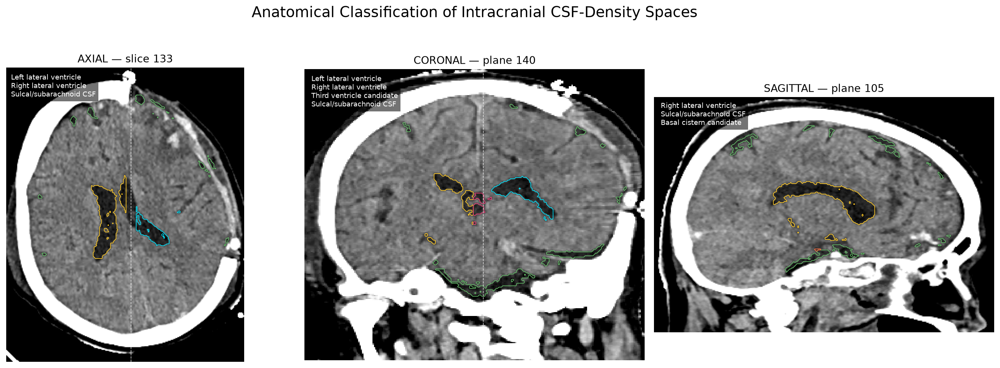

Saved: F:\csstdy\outputs\11_neural_ct_rendering\anatomical_classification\low_hu_anatomical_classification_multiplanar.png


In [10]:
v8_combined_ventricular = (
    v8_left_lateral | v8_right_lateral | v8_third_mask | v8_fourth_mask
)
v8_axial_profile = np.sum(
    v8_left_lateral | v8_right_lateral,
    axis=tuple(i for i in range(3) if i != v8_si_axis)
)
v8_coronal_profile = np.sum(
    v8_combined_ventricular,
    axis=tuple(i for i in range(3) if i != v8_ap_axis)
)
v8_sagittal_profile = np.sum(
    v8_combined_ventricular,
    axis=tuple(i for i in range(3) if i != v8_lr_axis)
)
v8_axial_index = int(np.argmax(v8_axial_profile))
v8_coronal_index = int(np.argmax(v8_coronal_profile))
v8_sagittal_index = int(np.argmax(v8_sagittal_profile))

v8_class_masks = [
    ("Left lateral ventricle", v8_left_lateral, "#00e5ff", v8_lateral_supported),
    ("Right lateral ventricle", v8_right_lateral, "#ffca28", v8_lateral_supported),
    ("Third ventricle candidate", v8_third_mask, "#ec407a", v8_third_supported),
    ("Fourth ventricle candidate", v8_fourth_mask, "#ab47bc", v8_fourth_supported),
    ("Sulcal/subarachnoid CSF", v8_peripheral_mask, "#66bb6a", v8_peripheral_supported),
    ("Basal cistern candidate", v8_basal_mask, "#ff7043", v8_basal_supported),
]

def v8_draw_anatomical_panel(ax, axis, index, title):
    ct_plane = v8_plane(v8_ct, axis, index)
    ax.imshow(ct_plane, cmap="gray", vmin=0, vmax=80)
    labels_here = []
    for name, mask, color, supported in v8_class_masks:
        if not supported:
            continue
        mask_plane = v8_plane(mask, axis, index)
        if mask_plane.any() and not mask_plane.all():
            ax.contour(mask_plane.astype(float), levels=[0.5], colors=[color], linewidths=0.75)
            labels_here.append((name, color))
    if axis in (v8_si_axis, v8_ap_axis):
        ax.axvline(v8_mid_index, color="white", linestyle="--", linewidth=0.7, alpha=0.8)
    if labels_here:
        label_text = "\n".join(name for name, _ in labels_here)
        ax.text(
            0.02, 0.98, label_text, transform=ax.transAxes, va="top", ha="left",
            fontsize=8, color="white",
            bbox=dict(facecolor="black", edgecolor="none", alpha=0.55, pad=3)
        )
    ax.set_title(title)
    ax.axis("off")

v8_fig, v8_axes = plt.subplots(1, 3, figsize=(17, 6), dpi=160)
v8_draw_anatomical_panel(v8_axes[0], v8_si_axis, v8_axial_index, f"AXIAL — slice {v8_axial_index}")
v8_draw_anatomical_panel(v8_axes[1], v8_ap_axis, v8_coronal_index, f"CORONAL — plane {v8_coronal_index}")
v8_draw_anatomical_panel(v8_axes[2], v8_lr_axis, v8_sagittal_index, f"SAGITTAL — plane {v8_sagittal_index}")
v8_fig.suptitle("Anatomical Classification of Intracranial CSF-Density Spaces", fontsize=17)
v8_fig.tight_layout(rect=(0, 0, 1, 0.94))
v8_multiplanar_path = v8_dir / "low_hu_anatomical_classification_multiplanar.png"
v8_fig.savefig(v8_multiplanar_path, dpi=240, bbox_inches="tight")
plt.show()
print(f"Saved: {v8_multiplanar_path}")

### 8.14 Ventricular-system 3D visualization

This is a new Plotly output. It shows the transparent TotalSegmentator brain, the separately classified left and right lateral-ventricular candidates, supported midline candidates, and an optional low-opacity peripheral CSF-candidate group. It does not modify the Section 7 3D file.

In [11]:
def v8_world_mesh(mask, step_size=1):
    mask_u8 = np.asarray(mask, dtype=np.uint8)
    if not mask_u8.any():
        return None
    vertices, faces, _, _ = measure.marching_cubes(
        mask_u8, level=0.5, step_size=int(step_size), allow_degenerate=False
    )
    return nib.affines.apply_affine(v8_crop_affine, vertices), faces

def v8_add_mesh(figure, mask, name, color, opacity, step_size=1, visible=True):
    mesh = v8_world_mesh(mask, step_size=step_size)
    if mesh is None:
        return
    vertices, faces = mesh
    figure.add_trace(go.Mesh3d(
        x=vertices[:, 0], y=vertices[:, 1], z=vertices[:, 2],
        i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
        name=name, color=color, opacity=opacity, visible=visible,
        flatshading=False,
        lighting=dict(ambient=0.52, diffuse=0.75, specular=0.18)
    ))

v8_figure_3d = go.Figure()
v8_add_mesh(v8_figure_3d, v8_brain, "TotalSegmentator brain", "#ef9a9a", 0.12, step_size=3)
v8_add_mesh(v8_figure_3d, v8_left_lateral, "Left lateral ventricular candidate", "#00e5ff", 0.92)
v8_add_mesh(v8_figure_3d, v8_right_lateral, "Right lateral ventricular candidate", "#ffca28", 0.92)
if v8_third_supported:
    v8_add_mesh(v8_figure_3d, v8_third_mask, "Third ventricular candidate", "#ec407a", 0.92)
if v8_fourth_supported:
    v8_add_mesh(v8_figure_3d, v8_fourth_mask, "Fourth ventricular candidate", "#ab47bc", 0.92)
if v8_basal_supported:
    v8_add_mesh(v8_figure_3d, v8_basal_mask, "Basal cistern candidate", "#ff7043", 0.75)
if v8_peripheral_supported:
    v8_add_mesh(
        v8_figure_3d, v8_peripheral_mask, "Peripheral subarachnoid CSF candidate",
        "#66bb6a", 0.08, step_size=3, visible="legendonly"
    )

v8_figure_3d.update_layout(
    title="CASE_001 — Anatomical Classification of CSF-Density Spaces",
    template="plotly_dark", width=1000, height=780,
    scene=dict(
        xaxis_title="Patient X (mm)", yaxis_title="Patient Y (mm)",
        zaxis_title="Patient Z (mm)", aspectmode="data"
    ),
    legend=dict(orientation="h")
)
v8_3d_path = v8_dir / "CASE_001_anatomical_csf_space_classification.html"
v8_figure_3d.write_html(
    str(v8_3d_path), include_plotlyjs="cdn", full_html=True,
    config={"displaylogo": False, "scrollZoom": True}
)
display(HTML(
    f'<p><b>Interactive anatomical 3D:</b> '
    f'<a href="{v8_3d_path.as_posix()}" target="_blank">{v8_3d_path.name}</a></p>'
))
print(f"Saved: {v8_3d_path}")

Saved: F:\csstdy\outputs\11_neural_ct_rendering\anatomical_classification\CASE_001_anatomical_csf_space_classification.html


### 8.15–8.17 Classification table and decision logic

Anatomical labels require agreement among HU, depth, position, persistence, laterality, and multiplanar extent. Perfect voxelwise reflection is not required: the Section 7 reflection Dice is overly strict for asymmetrical anatomy, pathology, and a threshold mask containing non-ventricular CSF. Horn-level subdivisions remain lower confidence because they are geometric approximations rather than atlas-based labels.

In [12]:
v8_classification_rows = []

def v8_add_classification(
    anatomical_class, side, subregion_id, mask, confidence, evidence, limitations
):
    stats = v8_mask_stats(mask)
    v8_classification_rows.append({
        "anatomical_class": anatomical_class,
        "side": side,
        "component_or_subregion_id": subregion_id,
        "voxel_count": stats["voxel_count"],
        "volume_mm3": stats["volume_mm3"],
        "mean_hu": stats["mean_hu"],
        "median_hu": stats["median_hu"],
        "centroid_world_mm": json.dumps(stats["centroid_world_mm"]),
        "slice_range": json.dumps(stats["slice_range"]),
        "median_boundary_distance_mm": stats["median_boundary_distance_mm"],
        "persistence_slices": stats["persistence_slices"],
        "classification_confidence": confidence,
        "evidence": evidence,
        "limitations": limitations,
    })

v8_lateral_evidence = (
    "0–20 HU; >10 mm boundary depth; bilateral central supratentorial position; "
    "midsagittal separation; consecutive-slice and multiplanar continuity"
)
v8_lateral_limit = (
    "CT-intensity and geometry classification; no dedicated ventricular atlas or manual ventricular mask"
)
v8_add_classification(
    "LEFT LATERAL VENTRICLE", "LEFT", "LV-left", v8_left_lateral,
    v8_lateral_confidence, v8_lateral_evidence, v8_lateral_limit
)
v8_add_classification(
    "RIGHT LATERAL VENTRICLE", "RIGHT", "LV-right", v8_right_lateral,
    v8_lateral_confidence, v8_lateral_evidence, v8_lateral_limit
)

for v8_side, v8_prefix, v8_masks in (
    ("LEFT", "LV-left", (
        ("ANTERIOR/FRONTAL HORN APPROXIMATION", v8_left_anterior),
        ("BODY/ATRIUM APPROXIMATION", v8_left_body),
        ("POSTERIOR/OCCIPITAL HORN APPROXIMATION", v8_left_posterior),
    )),
    ("RIGHT", "LV-right", (
        ("ANTERIOR/FRONTAL HORN APPROXIMATION", v8_right_anterior),
        ("BODY/ATRIUM APPROXIMATION", v8_right_body),
        ("POSTERIOR/OCCIPITAL HORN APPROXIMATION", v8_right_posterior),
    )),
):
    for v8_horn_name, v8_horn_mask in v8_masks:
        if v8_horn_mask.sum() * v8_voxel_volume >= 5.0:
            v8_add_classification(
                f"LATERAL VENTRICLE — {v8_horn_name}", v8_side,
                f"{v8_prefix}-{v8_horn_name.split()[0].lower()}", v8_horn_mask,
                "LOW",
                "Affine-derived anterior–posterior subdivision of the supported lateral ventricular candidate",
                "Approximate geometric horn label; not an atlas or expert segmentation",
            )

v8_add_classification(
    "THIRD VENTRICLE — ANATOMICAL CANDIDATE", "MIDLINE", "V3", v8_third_mask,
    v8_third_confidence,
    "Narrow deep 0–20 HU region close to the midsagittal plane with consecutive-slice support",
    "CT-only spatial heuristic; no dedicated ventricular atlas",
)
v8_add_classification(
    "FOURTH VENTRICLE — ANATOMICAL CANDIDATE", "MIDLINE", "V4", v8_fourth_mask,
    v8_fourth_confidence,
    "Central inferior/posterior-fossa 0–20 HU region with 3D persistence",
    "Low confidence without explicit cerebellum/brainstem anatomical labels",
)
v8_add_classification(
    "CORTICAL SULCAL / SUBARACHNOID CSF CANDIDATE", "BILATERAL", "PERIPHERAL",
    v8_peripheral_mask, v8_peripheral_confidence,
    "0–20 HU surface-following distribution within 8 mm of the brain boundary",
    "May include partial-volume or other peripheral low-attenuation voxels",
)
v8_add_classification(
    "BASAL CISTERN / CISTERNAL CSF CANDIDATE", "MIDLINE", "BASAL",
    v8_basal_mask, v8_basal_confidence,
    "Central inferior 0–20 HU position separated from the outer boundary",
    "Specific cistern identity is not resolved",
)

v8_classified_union = (
    v8_left_lateral | v8_right_lateral | v8_third_mask | v8_fourth_mask
    | v8_peripheral_mask | v8_basal_mask
)
v8_residual_uncertain = v8_native_low & ~v8_classified_union
v8_add_classification(
    "NON-CSF LOW-ATTENUATION / ARTEFACT — UNCERTAIN", "UNSPECIFIED", "RESIDUAL",
    v8_residual_uncertain, "UNRESOLVED",
    "Nominal low-HU voxels not meeting the anatomical rules for a named CSF space",
    "Intensity alone is nonspecific; expert review required",
)

v8_classification_df = pd.DataFrame(v8_classification_rows)
v8_classification_path = v8_dir / "anatomical_low_hu_classification.csv"
v8_classification_df.to_csv(v8_classification_path, index=False)
display(v8_classification_df)
print(f"Saved: {v8_classification_path}")

,anatomical_class,side,component_or_subregion_id,voxel_count,volume_mm3,mean_hu,median_hu,centroid_world_mm,slice_range,median_boundary_distance_mm,persistence_slices,classification_confidence,evidence,limitations
0,LEFT LATERAL VENTRICLE,LEFT,LV-left,19008,4403.018401,12.621423,13.0,"[-3.1377854318129152, 134.41071551837504, -511...","[87, 145]",33.792795,59,MODERATE,0–20 HU; >10 mm boundary depth; bilateral cent...,CT-intensity and geometry classification; no d...
1,RIGHT LATERAL VENTRICLE,RIGHT,LV-right,40915,9477.561967,12.134058,12.0,"[28.130276913056086, 145.89348879999102, -512....","[87, 145]",35.921005,59,MODERATE,0–20 HU; >10 mm boundary depth; bilateral cent...,CT-intensity and geometry classification; no d...
2,LATERAL VENTRICLE — ANTERIOR/FRONTAL HORN APPR...,LEFT,LV-left-anterior/frontal,2147,497.331676,16.226362,17.0,"[-4.694322535421989, 160.19175787020907, -519....","[87, 145]",25.920306,34,LOW,Affine-derived anterior–posterior subdivision ...,Approximate geometric horn label; not an atlas...
3,LATERAL VENTRICLE — BODY/ATRIUM APPROXIMATION,LEFT,LV-left-body/atrium,6116,1416.711939,11.710432,11.0,"[0.7178643197308503, 140.91369841689766, -509....","[87, 145]",38.913429,30,LOW,Affine-derived anterior–posterior subdivision ...,Approximate geometric horn label; not an atlas...
4,LATERAL VENTRICLE — POSTERIOR/OCCIPITAL HORN A...,LEFT,LV-left-posterior/occipital,10745,2488.974785,12.419637,12.0,"[-5.021384195795491, 125.55784056846792, -510....","[87, 141]",33.738708,38,LOW,Affine-derived anterior–posterior subdivision ...,Approximate geometric horn label; not an atlas...
5,LATERAL VENTRICLE — ANTERIOR/FRONTAL HORN APPR...,RIGHT,LV-right-anterior/frontal,19465,4508.878008,11.288569,11.0,"[28.03580842957593, 159.57172839059152, -514.2...","[87, 145]",34.480864,59,LOW,Affine-derived anterior–posterior subdivision ...,Approximate geometric horn label; not an atlas...
6,LATERAL VENTRICLE — BODY/ATRIUM APPROXIMATION,RIGHT,LV-right-body/atrium,11018,2552.212581,12.340534,12.0,"[27.05144769333088, 142.4012023242335, -512.74...","[87, 145]",37.248840,59,LOW,Affine-derived anterior–posterior subdivision ...,Approximate geometric horn label; not an atlas...
7,LATERAL VENTRICLE — POSTERIOR/OCCIPITAL HORN A...,RIGHT,LV-right-posterior/occipital,10432,2416.471378,13.493577,14.0,"[29.44597566438599, 124.05981153377726, -510.4...","[87, 142]",37.161537,56,LOW,Affine-derived anterior–posterior subdivision ...,Approximate geometric horn label; not an atlas...
8,THIRD VENTRICLE — ANATOMICAL CANDIDATE,MIDLINE,V3,1758,407.223608,13.585324,14.0,"[17.1608045011657, 136.06123530200182, -513.73...","[97, 127]",38.276233,31,MODERATE,Narrow deep 0–20 HU region close to the midsag...,CT-only spatial heuristic; no dedicated ventri...
9,FOURTH VENTRICLE — ANATOMICAL CANDIDATE,MIDLINE,V4,2791,646.508015,12.606593,13.0,"[13.85234489222232, 117.76781458224245, -544.4...","[53, 85]",22.801452,21,LOW,Central inferior/posterior-fossa 0–20 HU regio...,Low confidence without explicit cerebellum/bra...


Saved: F:\csstdy\outputs\11_neural_ct_rendering\anatomical_classification\anatomical_low_hu_classification.csv


### 8.18 Machine-readable summary

The JSON summary records the dominant anatomical classification, confidence, individual CSF-space candidates, report and hyperdensity concordance, supporting measurements, and limitations.

In [13]:
def v8_json_safe(value):
    if isinstance(value, dict):
        return {str(k): v8_json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [v8_json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return v8_json_safe(value.tolist())
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

v8_dominant_class = (
    "bilateral lateral ventricular CSF-density spaces"
    if v8_lateral_supported else "central ventricular/CSF candidate, incompletely resolved"
)
v8_dominant_confidence = v8_lateral_confidence
v8_summary = {
    "case": "CASE_001",
    "dominant_anatomical_class": v8_dominant_class,
    "dominant_class_confidence": v8_dominant_confidence,
    "left_lateral_ventricle": {"supported": v8_lateral_supported, "confidence": v8_lateral_confidence, **v8_left_stats},
    "right_lateral_ventricle": {"supported": v8_lateral_supported, "confidence": v8_lateral_confidence, **v8_right_stats},
    "third_ventricle": {"supported": v8_third_supported, "confidence": v8_third_confidence, **v8_third_stats},
    "fourth_ventricle": {"supported": v8_fourth_supported, "confidence": v8_fourth_confidence, **v8_fourth_stats},
    "subarachnoid_sulcal_csf": {
        "supported": v8_peripheral_supported, "confidence": v8_peripheral_confidence, **v8_peripheral_stats
    },
    "basal_cistern_candidate": {
        "supported": v8_basal_supported, "confidence": v8_basal_confidence, **v8_basal_stats
    },
    "report_ivh_concordance": {
        "report_level_ivh_available": v8_report_ivh_available,
        "posterior_bilateral_regions_classified": v8_posterior_regions_supported,
        "spatially_concordant": v8_report_ivh_concordance,
        "annotation_file": str(v8_annotation_path) if v8_annotation_path else None,
        "ground_truth_role": "report-level supporting evidence only; not voxel-level ground truth",
    },
    "hyperdense_material_concordance": {
        "present_within_or_adjacent_to_posterior_regions": v8_hyperdense_concordance,
        "exploratory_measurements": v8_hyperdensity.to_dict(orient="records"),
        "interpretation": "Threshold-based concordance only; not independent hemorrhage diagnosis",
    },
    "supporting_measurements": {
        "section7_verified_results": v8_verified_results.to_dict(orient="records")[0],
        "deep_boundary_sensitivity": v8_depth_sensitivity.to_dict(orient="records"),
        "nominal_deep_boundary_criterion_mm": v8_nominal_depth_mm,
        "classified_left_right_volume_balance": v8_lateral_balance,
        "affine_axis_codes": list(v8_axcodes),
        "estimated_midsagittal_voxel_coordinate": v8_mid_index,
    },
    "limitations": [
        "Anatomical labels are CT-intensity and geometry based rather than expert manual segmentations.",
        "The TotalSegmentator brain mask is not a dedicated ventricular segmentation.",
        "A 26-connected low-HU mask can bridge anatomically distinct spaces.",
        "Horn-level subdivisions are approximate and not atlas registered.",
        "Low attenuation is not specific to cerebrospinal fluid.",
        "Hyperdense thresholds do not independently diagnose hemorrhage.",
        "The structured annotation is report-level rather than voxel-level ground truth.",
        "Definitive interpretation requires expert radiological review."
    ],
}
v8_summary_path = v8_dir / "anatomical_low_hu_classification_summary.json"
v8_summary_path.write_text(
    json.dumps(v8_json_safe(v8_summary), indent=2, ensure_ascii=False),
    encoding="utf-8"
)
print(f"Saved: {v8_summary_path}")

Saved: F:\csstdy\outputs\11_neural_ct_rendering\anatomical_classification\anatomical_low_hu_classification_summary.json


### 8.19 Final anatomical classification

The final output names anatomy only where multiple independent features agree. It separately reports confidence for the lateral, third, fourth, peripheral, and basal candidates and carefully distinguishes report concordance from independent diagnosis.

In [14]:
print("-" * 60)
print("ANATOMICAL CLASSIFICATION OF THE DARK SPACES")
print("-" * 60)
print()
print("Dominant classification:")
print(v8_dominant_class)
print()
print("Confidence:")
print(v8_dominant_confidence)
print()
print("Supporting evidence:")
print(f"- native CT HU: left mean {v8_left_stats['mean_hu']:.2f} HU; right mean {v8_right_stats['mean_hu']:.2f} HU")
print("- location: deep, central, supratentorial regions on opposite sides of the affine-derived midsagittal plane")
print(f"- 3D persistence: left {v8_left_stats['persistence_slices']} slices; right {v8_right_stats['persistence_slices']} slices")
print(f"- bilateral pattern: classified-volume balance {v8_lateral_balance:.3f}")
print(f"- multiplanar morphology: axis spans left {v8_left_stats['axis_spans']}; right {v8_right_stats['axis_spans']}")
print(
    f"- boundary distance: left median {v8_left_stats['median_boundary_distance_mm']:.2f} mm; "
    f"right median {v8_right_stats['median_boundary_distance_mm']:.2f} mm"
)
print(f"- report concordance: {v8_report_ivh_concordance}")
print()
print("Additional CSF spaces:")
print(f"- Third ventricle: {v8_third_confidence}")
print(f"- Fourth ventricle: {v8_fourth_confidence}")
print(f"- Cortical sulcal/subarachnoid CSF: {v8_peripheral_confidence}")
print(f"- Basal cisternal CSF: {v8_basal_confidence}")
print()
print("Posterior lateral ventricular finding:")
if v8_posterior_regions_supported:
    print(
        "The posterior subdivisions correspond anatomically to approximate occipital/posterior "
        "horn regions of the left and right lateral ventricles."
    )
else:
    print("Posterior horn regions were not reliably separable.")
print()
print("Structured report:")
if v8_report_ivh_available:
    print("Likely IVH — bilateral lateral ventricular occipital horns (report-level information).")
else:
    print("No matching report-level IVH entry was available.")
print()
print("FINAL INTERPRETATION:")
if v8_lateral_supported:
    print(
        "The dominant dark central structures are most consistent with CSF-density spaces of the "
        "ventricular system, predominantly the left and right lateral ventricles."
    )
else:
    print(
        "The central low-HU structures cannot be assigned confidently beyond a ventricular/CSF candidate."
    )
if v8_peripheral_supported:
    print("Additional peripheral dark linear spaces are compatible with sulcal/subarachnoid CSF.")
if v8_report_ivh_concordance:
    print(
        "The posterior ventricular regions correspond to approximate occipital horns, where the "
        "structured report independently records likely intraventricular hemorrhage."
    )
if v8_hyperdense_concordance:
    print(
        "Relatively hyperdense material is present within/adjacent to these posterior ventricular "
        "spaces, providing imaging concordance with the report-level IVH finding, although this "
        "threshold-based analysis is not an independent diagnostic test."
    )
print("Definitive anatomical or pathological interpretation requires expert radiological review.")
print()
print("-" * 60)
print("Section 8 appended successfully; Sections 1–7 and all existing outputs were preserved.")

------------------------------------------------------------
ANATOMICAL CLASSIFICATION OF THE DARK SPACES
------------------------------------------------------------

Dominant classification:
bilateral lateral ventricular CSF-density spaces

Confidence:
MODERATE

Supporting evidence:
- native CT HU: left mean 12.62 HU; right mean 12.13 HU
- location: deep, central, supratentorial regions on opposite sides of the affine-derived midsagittal plane
- 3D persistence: left 59 slices; right 59 slices
- bilateral pattern: classified-volume balance 0.465
- multiplanar morphology: axis spans left [48, 96, 59]; right [48, 96, 59]
- boundary distance: left median 33.79 mm; right median 35.92 mm
- report concordance: True

Additional CSF spaces:
- Third ventricle: MODERATE
- Fourth ventricle: LOW
- Cortical sulcal/subarachnoid CSF: MODERATE
- Basal cisternal CSF: LOW

Posterior lateral ventricular finding:
The posterior subdivisions correspond anatomically to approximate occipital/posterior horn r

## 9. Triplanar Review of Structured Report Findings

This section checks every finding in CASE_001_structured_annotations.csv on **axial, coronal, and sagittal views of the original CT reconstructions**.

The CSV is report-level information, not a voxel-level annotation. Therefore, contours, crosshairs, and slice centres below are **report-guided review regions or exploratory intensity candidates**, not lesion segmentations and not independent diagnostic detections. BRAIN_HR36F is used for intracranial findings and BONE_HR60F for the two suspected fractures. Final interpretation requires expert radiological review.

### 9.1 Source verification and patient-space orientation

The two original reconstructions, the TotalSegmentator brain mask, and the sharper skull mask are loaded on their full native grid. Their shapes and affines must match before any plane is displayed. Anatomical left/right, anterior/posterior, and superior/inferior directions are derived from the NIfTI affine rather than assumed.

In [1]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy import ndimage as ndi

v9_root = Path(globals().get("PROJECT_ROOT", r"F:\csstdy"))
v9_output_root = v9_root / "outputs" / "11_neural_ct_rendering"
v9_dir = v9_output_root / "report_finding_triplanar_review"
if v9_dir.exists():
    raise FileExistsError(f"{v9_dir} already exists; refusing to overwrite a prior Section 9 analysis.")
v9_dir.mkdir(parents=True, exist_ok=False)

v9_brain_ct_path = (
    v9_root / "outputs" / "09_totalsegmentator_dl_skull_brain"
    / "input" / "CASE_001_brain_kernel_ct.nii.gz"
)
v9_bone_ct_path = (
    v9_root / "outputs" / "10_totalsegmentator_sharp_skull"
    / "input" / "CASE_001_bone_kernel_ct.nii.gz"
)
v9_brain_mask_path = (
    v9_root / "outputs" / "09_totalsegmentator_dl_skull_brain"
    / "segmentations" / "brain.nii.gz"
)
v9_skull_mask_path = (
    v9_root / "outputs" / "10_totalsegmentator_sharp_skull"
    / "craniofacial_segmentations" / "skull.nii.gz"
)
v9_annotation_matches = list(v9_root.rglob("CASE_001_structured_annotations.csv"))
if not v9_annotation_matches:
    raise FileNotFoundError("CASE_001_structured_annotations.csv")
v9_annotation_path = v9_annotation_matches[0]

for v9_path in (
    v9_brain_ct_path, v9_bone_ct_path, v9_brain_mask_path,
    v9_skull_mask_path, v9_annotation_path
):
    if not v9_path.exists():
        raise FileNotFoundError(v9_path)

v9_brain_ct_img = nib.load(str(v9_brain_ct_path))
v9_bone_ct_img = nib.load(str(v9_bone_ct_path))
v9_brain_mask_img = nib.load(str(v9_brain_mask_path))
v9_skull_mask_img = nib.load(str(v9_skull_mask_path))
v9_brain_ct = np.asarray(v9_brain_ct_img.dataobj, dtype=np.float32).copy()
v9_bone_ct = np.asarray(v9_bone_ct_img.dataobj, dtype=np.float32).copy()
v9_brain = (np.asarray(v9_brain_mask_img.dataobj) > 0).copy()
v9_skull = (np.asarray(v9_skull_mask_img.dataobj) > 0).copy()

v9_shapes = {v9_brain_ct.shape, v9_bone_ct.shape, v9_brain.shape, v9_skull.shape}
if len(v9_shapes) != 1:
    raise ValueError(f"Native shapes are not aligned: {v9_shapes}")
v9_affine = np.asarray(v9_brain_ct_img.affine, dtype=np.float64)
for v9_img in (v9_bone_ct_img, v9_brain_mask_img, v9_skull_mask_img):
    if not np.allclose(v9_img.affine, v9_affine, atol=1e-5):
        raise ValueError("A source affine differs from the BRAIN_HR36F affine.")

v9_axcodes = nib.aff2axcodes(v9_affine)
v9_spacing = np.linalg.norm(v9_affine[:3, :3], axis=0)
v9_voxel_volume = float(abs(np.linalg.det(v9_affine[:3, :3])))
v9_lr_axis = next(i for i, c in enumerate(v9_axcodes) if c in ("L", "R"))
v9_ap_axis = next(i for i, c in enumerate(v9_axcodes) if c in ("A", "P"))
v9_si_axis = next(i for i, c in enumerate(v9_axcodes) if c in ("S", "I"))

v9_brain_coords = np.argwhere(v9_brain)
v9_bbox_min = v9_brain_coords.min(axis=0)
v9_bbox_max = v9_brain_coords.max(axis=0)
v9_bbox_span = np.maximum(v9_bbox_max - v9_bbox_min, 1)
v9_mid = 0.5 * (v9_bbox_min + v9_bbox_max)
v9_grid = np.indices(v9_brain_ct.shape, sparse=True)
v9_lr_mm = (v9_grid[v9_lr_axis] - v9_mid[v9_lr_axis]) * v9_spacing[v9_lr_axis]
v9_ap_fraction = (v9_grid[v9_ap_axis] - v9_bbox_min[v9_ap_axis]) / v9_bbox_span[v9_ap_axis]
v9_si_fraction = (v9_grid[v9_si_axis] - v9_bbox_min[v9_si_axis]) / v9_bbox_span[v9_si_axis]
v9_inside_distance = ndi.distance_transform_edt(
    v9_brain, sampling=tuple(v9_spacing)
).astype(np.float32)
v9_distance_to_brain = ndi.distance_transform_edt(
    ~v9_brain, sampling=tuple(v9_spacing)
).astype(np.float32)
v9_near_brain_outer = (~v9_brain) & (v9_distance_to_brain <= 15.0)

if v9_axcodes[v9_lr_axis] == "L":
    v9_left = v9_grid[v9_lr_axis] > v9_mid[v9_lr_axis]
    v9_right = v9_grid[v9_lr_axis] < v9_mid[v9_lr_axis]
else:
    v9_left = v9_grid[v9_lr_axis] < v9_mid[v9_lr_axis]
    v9_right = v9_grid[v9_lr_axis] > v9_mid[v9_lr_axis]

v9_annotations = pd.read_csv(v9_annotation_path)
v9_required_columns = ["finding", "report_status", "region", "reconstruction", "certainty"]
if list(v9_annotations.columns) != v9_required_columns:
    raise ValueError(f"Unexpected annotation columns: {list(v9_annotations.columns)}")

print(f"Original grid: {v9_brain_ct.shape}; axcodes: {v9_axcodes}")
print(f"Voxel sizes: {np.round(v9_spacing, 4)} mm")
print(f"Report rows: {len(v9_annotations)}")
print("BRAIN_HR36F and BONE_HR60F are spatially aligned.")

Original grid: (512, 512, 227); axcodes: ('L', 'A', 'S')
Voxel sizes: [0.5557 0.5557 0.75  ] mm
Report rows: 9
BRAIN_HR36F and BONE_HR60F are spatially aligned.


### 9.2 Structured report entries

All nine report entries are retained with their original status and certainty. “Reported,” “Likely,” and “Suspected” describe the source report and must not be interpreted as confidence from the automated visualization.

In [2]:
display(v9_annotations)

,finding,report_status,region,reconstruction,certainty
0,Hemorrhagic contusion,Reported,Left frontal and temporal lobes,BRAIN_HR36F,Explicitly reported
1,Acute subdural hematoma (SDH),Reported,Left fronto-temporo-parietal region,BRAIN_HR36F,Explicitly reported
2,Posterior interhemispheric SDH,Reported,Posterior interhemispheric region,BRAIN_HR36F,Explicitly reported
3,Intraventricular hemorrhage (IVH),Likely,Bilateral lateral ventricular occipital horns,BRAIN_HR36F,Reported as likely
4,Subarachnoid hemorrhage (SAH),Likely,Left frontoparietal lobes,BRAIN_HR36F,Reported as likely
5,Mass effect / midline shift,Reported,Midline; approximately 3 mm shift to the right,BRAIN_HR36F,Explicitly reported
6,Postoperative extra-axial collection,Reported,Extra-axial postoperative region,BRAIN_HR36F,Explicitly reported
7,Right sphenoid bone fracture,Suspected,Right sphenoid bone,BONE_HR60F,Reported as suspected
8,Right occipital bone fracture,Suspected,Right occipital bone,BONE_HR60F,Reported as suspected


### 9.3 Report-guided candidate construction

For hemorrhage-related rows, exploratory 35–100 HU material is localized within the report-specified anatomical territory. Subdural and postoperative candidates additionally use proximity to the brain boundary. IVH review uses bilateral posterior ventricular neighbourhoods derived from the same anatomical rules documented in Section 8. Fracture views use the original bone reconstruction and high bone-gradient points within report-guided sphenoid and occipital territories.

These rules select useful review centres; they do not create diagnostic ground-truth masks.

In [3]:
v9_hyperdense_brain = (
    np.isfinite(v9_brain_ct) & (v9_brain_ct >= 35.0) & (v9_brain_ct <= 100.0)
)
v9_low_collection = (
    np.isfinite(v9_brain_ct) & (v9_brain_ct >= -10.0) & (v9_brain_ct <= 35.0)
)
v9_central_low = (
    v9_brain & (v9_inside_distance > 10.0)
    & (v9_brain_ct >= 0.0) & (v9_brain_ct <= 20.0)
)

v9_lateral_roi = (
    v9_central_low
    & (np.abs(v9_lr_mm) >= 3.0) & (np.abs(v9_lr_mm) <= 30.0)
    & (v9_ap_fraction >= 0.32) & (v9_ap_fraction <= 0.68)
    & (v9_si_fraction >= 0.35) & (v9_si_fraction <= 0.68)
)
v9_left_lateral = v9_lateral_roi & v9_left
v9_right_lateral = v9_lateral_roi & v9_right
v9_left_posterior = v9_left_lateral & (v9_ap_fraction < 0.44)
v9_right_posterior = v9_right_lateral & (v9_ap_fraction < 0.44)
v9_posterior_ventricular = v9_left_posterior | v9_right_posterior
v9_near_posterior_ventricles = (
    ndi.distance_transform_edt(~v9_posterior_ventricular, sampling=tuple(v9_spacing)) <= 3.0
)

v9_rois = {
    "Hemorrhagic contusion": (
        v9_brain & v9_left
        & (
            ((v9_ap_fraction >= 0.55) & (v9_si_fraction >= 0.35))
            | ((v9_ap_fraction >= 0.35) & (v9_ap_fraction < 0.65)
               & (v9_si_fraction >= 0.18) & (v9_si_fraction < 0.50))
        )
    ),
    "Acute subdural hematoma (SDH)": (
        (v9_brain | v9_near_brain_outer) & v9_left
        & (v9_ap_fraction >= 0.28) & (v9_ap_fraction <= 0.88)
        & (v9_si_fraction >= 0.20) & (v9_si_fraction <= 0.88)
        & ((v9_inside_distance <= 10.0) | v9_near_brain_outer)
    ),
    "Posterior interhemispheric SDH": (
        (v9_brain | v9_near_brain_outer)
        & (np.abs(v9_lr_mm) <= 7.0)
        & (v9_ap_fraction <= 0.46)
        & (v9_si_fraction >= 0.38)
    ),
    "Intraventricular hemorrhage (IVH)": (
        v9_brain & v9_near_posterior_ventricles
    ),
    "Subarachnoid hemorrhage (SAH)": (
        v9_brain & v9_left
        & (v9_ap_fraction >= 0.43)
        & (v9_si_fraction >= 0.42)
        & (v9_inside_distance <= 12.0)
    ),
    "Mass effect / midline shift": (
        v9_brain
        & (np.abs(v9_lr_mm) <= 15.0)
        & (v9_ap_fraction >= 0.30) & (v9_ap_fraction <= 0.72)
        & (v9_si_fraction >= 0.34) & (v9_si_fraction <= 0.72)
    ),
    "Postoperative extra-axial collection": (
        v9_near_brain_outer & v9_left
        & (v9_ap_fraction >= 0.30) & (v9_ap_fraction <= 0.86)
        & (v9_si_fraction >= 0.30) & (v9_si_fraction <= 0.88)
    ),
    "Right sphenoid bone fracture": (
        v9_skull & v9_right
        & (v9_ap_fraction >= 0.52)
        & (v9_si_fraction >= 0.02) & (v9_si_fraction <= 0.38)
        & (np.abs(v9_lr_mm) >= 18.0)
    ),
    "Right occipital bone fracture": (
        v9_skull & v9_right
        & (v9_ap_fraction <= 0.38)
        & (v9_si_fraction >= 0.12) & (v9_si_fraction <= 0.58)
        & (np.abs(v9_lr_mm) >= 25.0)
    ),
}

v9_candidate_masks = {
    "Hemorrhagic contusion": v9_rois["Hemorrhagic contusion"] & v9_hyperdense_brain,
    "Acute subdural hematoma (SDH)": v9_rois["Acute subdural hematoma (SDH)"] & v9_hyperdense_brain,
    "Posterior interhemispheric SDH": v9_rois["Posterior interhemispheric SDH"] & v9_hyperdense_brain,
    "Intraventricular hemorrhage (IVH)": v9_rois["Intraventricular hemorrhage (IVH)"] & v9_hyperdense_brain,
    "Subarachnoid hemorrhage (SAH)": v9_rois["Subarachnoid hemorrhage (SAH)"] & v9_hyperdense_brain,
    "Mass effect / midline shift": v9_rois["Mass effect / midline shift"],
    "Postoperative extra-axial collection": (
        v9_rois["Postoperative extra-axial collection"] & v9_low_collection
    ),
}

v9_bone_gradient_squared = np.zeros(v9_bone_ct.shape, dtype=np.float32)
for v9_axis in range(3):
    v9_axis_gradient = ndi.sobel(v9_bone_ct, axis=v9_axis, mode="nearest")
    v9_bone_gradient_squared += v9_axis_gradient * v9_axis_gradient
v9_bone_gradient = np.sqrt(v9_bone_gradient_squared, dtype=np.float32)
del v9_bone_gradient_squared, v9_axis_gradient
for v9_finding in ("Right sphenoid bone fracture", "Right occipital bone fracture"):
    v9_roi = v9_rois[v9_finding]
    v9_values = v9_bone_gradient[v9_roi]
    v9_cutoff = np.percentile(v9_values, 85) if v9_values.size else np.inf
    v9_candidate_masks[v9_finding] = v9_roi & (v9_bone_gradient >= v9_cutoff)

def v9_review_centre(mask, fallback_roi):
    mask = np.asarray(mask, dtype=bool)
    if mask.any():
        density = ndi.gaussian_filter(mask.astype(np.float32), sigma=(4.0, 4.0, 2.0))
        coordinate = np.array(np.unravel_index(np.argmax(density), density.shape), dtype=int)
        return coordinate, "candidate-density maximum"
    coords = np.argwhere(fallback_roi)
    if coords.size:
        return np.rint(coords.mean(axis=0)).astype(int), "anatomical-ROI centroid fallback"
    return np.rint(v9_mid).astype(int), "brain-centre fallback"

v9_review_centres = {}
for v9_finding in v9_annotations["finding"]:
    v9_centre, v9_method = v9_review_centre(
        v9_candidate_masks[v9_finding], v9_rois[v9_finding]
    )
    v9_review_centres[v9_finding] = {"voxel": v9_centre, "method": v9_method}

display(pd.DataFrame([
    {
        "finding": finding,
        "candidate_voxels": int(v9_candidate_masks[finding].sum()),
        "review_centre_voxel": json.dumps(v9_review_centres[finding]["voxel"].tolist()),
        "selection_method": v9_review_centres[finding]["method"],
    }
    for finding in v9_annotations["finding"]
]))

,finding,candidate_voxels,review_centre_voxel,selection_method
0,Hemorrhagic contusion,568399,"[281, 362, 114]",candidate-density maximum
1,Acute subdural hematoma (SDH),442911,"[239, 353, 88]",candidate-density maximum
2,Posterior interhemispheric SDH,221570,"[227, 176, 99]",candidate-density maximum
3,Intraventricular hemorrhage (IVH),48109,"[219, 236, 105]",candidate-density maximum
4,Subarachnoid hemorrhage (SAH),253699,"[282, 361, 115]",candidate-density maximum
5,Mass effect / midline shift,397712,"[218, 230, 94]",candidate-density maximum
6,Postoperative extra-axial collection,131314,"[322, 347, 91]",candidate-density maximum
7,Right sphenoid bone fracture,29954,"[110, 336, 50]",candidate-density maximum
8,Right occipital bone fracture,23796,"[164, 228, 56]",candidate-density maximum


### 9.4 Axial, coronal, and sagittal images for every finding

Each row receives a dedicated three-plane figure centred on the report-guided review coordinate. The yellow crosshair marks the review centre. Cyan contours show only an exploratory intensity/geometry candidate. For midline shift, a white dashed line marks the affine-derived midsagittal plane and a magenta dotted line marks the report’s approximate 3 mm rightward displacement as a visual reference—not an independent automated measurement.

In [4]:
v9_colours = {
    "candidate": "#00e5ff",
    "crosshair": "#ffeb3b",
    "midsagittal": "#ffffff",
    "reported_shift": "#ff4081",
}

def v9_plane(array, orientation, coordinate):
    x, y, z = [int(v) for v in coordinate]
    if orientation == "AXIAL":
        return np.rot90(array[:, :, z]), (x, array.shape[1] - 1 - y)
    if orientation == "CORONAL":
        return np.rot90(array[:, y, :]), (x, array.shape[2] - 1 - z)
    if orientation == "SAGITTAL":
        return np.rot90(array[x, :, :]), (y, array.shape[2] - 1 - z)
    raise ValueError(orientation)

def v9_draw_plane(ax, volume, candidate, orientation, coordinate, window, finding):
    image_plane, (cross_x, cross_y) = v9_plane(volume, orientation, coordinate)
    mask_plane, _ = v9_plane(candidate, orientation, coordinate)
    ax.imshow(image_plane, cmap="gray", vmin=window[0], vmax=window[1], interpolation="nearest")
    if mask_plane.any() and not mask_plane.all() and finding != "Mass effect / midline shift":
        ax.contour(
            mask_plane.astype(float), levels=[0.5],
            colors=[v9_colours["candidate"]], linewidths=0.55
        )
    ax.axvline(cross_x, color=v9_colours["crosshair"], linewidth=0.65, alpha=0.9)
    ax.axhline(cross_y, color=v9_colours["crosshair"], linewidth=0.65, alpha=0.9)

    if finding == "Mass effect / midline shift" and orientation in ("AXIAL", "CORONAL"):
        mid_x = float(v9_mid[v9_lr_axis])
        # LAS means decreasing LR index points right; reverse this when the affine says R.
        right_sign = -1.0 if v9_axcodes[v9_lr_axis] == "L" else 1.0
        reported_shift_x = mid_x + right_sign * (3.0 / v9_spacing[v9_lr_axis])
        ax.axvline(
            mid_x, color=v9_colours["midsagittal"], linestyle="--",
            linewidth=1.0, label="Affine midsagittal reference"
        )
        ax.axvline(
            reported_shift_x, color=v9_colours["reported_shift"], linestyle=":",
            linewidth=1.2, label="Report: ~3 mm right"
        )
        ax.legend(loc="lower right", fontsize=7, framealpha=0.65)

    ax.set_title(orientation)
    ax.axis("off")

def v9_safe_name(text):
    return re.sub(r"[^A-Za-z0-9]+", "_", text).strip("_").lower()

v9_figure_paths = {}
for _, v9_row in v9_annotations.iterrows():
    v9_finding = v9_row["finding"]
    v9_coordinate = v9_review_centres[v9_finding]["voxel"]
    v9_use_bone = str(v9_row["reconstruction"]).upper().startswith("BONE")
    v9_volume = v9_bone_ct if v9_use_bone else v9_brain_ct
    v9_window = (-200.0, 2000.0) if v9_use_bone else (0.0, 100.0)
    v9_candidate = v9_candidate_masks[v9_finding]

    v9_fig, v9_axes = plt.subplots(1, 3, figsize=(16, 5.8), dpi=150)
    for v9_ax, v9_orientation in zip(v9_axes, ("AXIAL", "CORONAL", "SAGITTAL")):
        v9_draw_plane(
            v9_ax, v9_volume, v9_candidate, v9_orientation,
            v9_coordinate, v9_window, v9_finding
        )
    v9_world = nib.affines.apply_affine(v9_affine, v9_coordinate)
    v9_fig.suptitle(
        f"{v9_finding}\n"
        f"Report: {v9_row['report_status']} | Region: {v9_row['region']} | "
        f"{v9_row['reconstruction']} | {v9_row['certainty']}\n"
        f"Report-guided review centre: world {np.round(v9_world, 1)} mm",
        fontsize=12
    )
    v9_fig.text(
        0.5, 0.015,
        "Original CT triplanar review; crosshair/contour is not a diagnostic segmentation.",
        ha="center", fontsize=9
    )
    v9_fig.tight_layout(rect=(0, 0.05, 1, 0.86))
    v9_path = v9_dir / f"{v9_safe_name(v9_finding)}_triplanar.png"
    v9_fig.savefig(v9_path, dpi=220, bbox_inches="tight")
    plt.close(v9_fig)
    v9_figure_paths[v9_finding] = v9_path

print(f"Saved {len(v9_figure_paths)} individual triplanar figures.")
for v9_finding, v9_path in v9_figure_paths.items():
    print(f"- {v9_finding}: {v9_path.name}")

Saved 9 individual triplanar figures.
- Hemorrhagic contusion: hemorrhagic_contusion_triplanar.png
- Acute subdural hematoma (SDH): acute_subdural_hematoma_sdh_triplanar.png
- Posterior interhemispheric SDH: posterior_interhemispheric_sdh_triplanar.png
- Intraventricular hemorrhage (IVH): intraventricular_hemorrhage_ivh_triplanar.png
- Subarachnoid hemorrhage (SAH): subarachnoid_hemorrhage_sah_triplanar.png
- Mass effect / midline shift: mass_effect_midline_shift_triplanar.png
- Postoperative extra-axial collection: postoperative_extra_axial_collection_triplanar.png
- Right sphenoid bone fracture: right_sphenoid_bone_fracture_triplanar.png
- Right occipital bone fracture: right_occipital_bone_fracture_triplanar.png


### 9.5 Combined three-plane review sheet

The following contact sheet places all nine report entries in rows, with axial, coronal, and sagittal original-CT views in columns. Individual high-resolution PNG files are also saved for closer inspection.

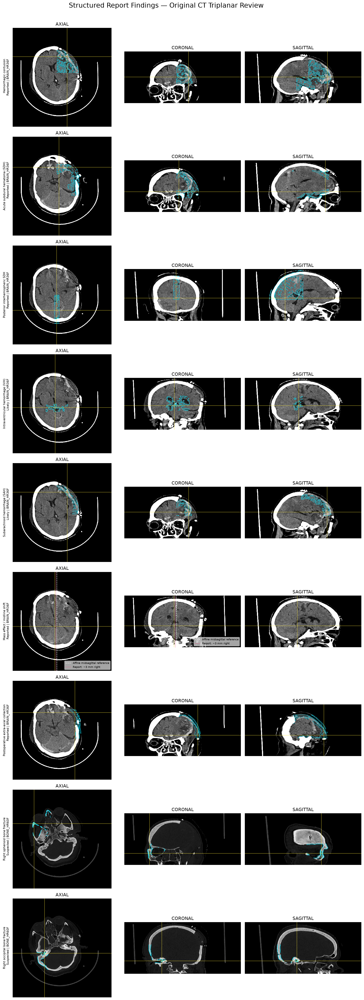

Saved: F:\csstdy\outputs\11_neural_ct_rendering\report_finding_triplanar_review\all_report_findings_triplanar_review.png


In [5]:
v9_combined_fig, v9_combined_axes = plt.subplots(
    len(v9_annotations), 3, figsize=(15, 38), dpi=120
)
for v9_row_index, (_, v9_row) in enumerate(v9_annotations.iterrows()):
    v9_finding = v9_row["finding"]
    v9_coordinate = v9_review_centres[v9_finding]["voxel"]
    v9_use_bone = str(v9_row["reconstruction"]).upper().startswith("BONE")
    v9_volume = v9_bone_ct if v9_use_bone else v9_brain_ct
    v9_window = (-200.0, 2000.0) if v9_use_bone else (0.0, 100.0)
    for v9_column, v9_orientation in enumerate(("AXIAL", "CORONAL", "SAGITTAL")):
        v9_ax = v9_combined_axes[v9_row_index, v9_column]
        v9_draw_plane(
            v9_ax, v9_volume, v9_candidate_masks[v9_finding],
            v9_orientation, v9_coordinate, v9_window, v9_finding
        )
        if v9_column == 0:
            v9_ax.text(
                -0.03, 0.5,
                f"{v9_finding}\n{v9_row['report_status']} | {v9_row['reconstruction']}",
                transform=v9_ax.transAxes, rotation=90, va="center", ha="right", fontsize=8
            )
v9_combined_fig.suptitle(
    "Structured Report Findings — Original CT Triplanar Review",
    fontsize=18, y=0.995
)
v9_combined_fig.tight_layout(rect=(0.08, 0.005, 1, 0.99), h_pad=1.2)
v9_combined_path = v9_dir / "all_report_findings_triplanar_review.png"
v9_combined_fig.savefig(v9_combined_path, dpi=180, bbox_inches="tight")
plt.close(v9_combined_fig)
display(Image(filename=str(v9_combined_path)))
print(f"Saved: {v9_combined_path}")

### 9.6 Finding-by-finding review table

The table records the exact report metadata, selected patient/world coordinate, plane indices, candidate size, source reconstruction, review basis, and limitations. “Candidate present” means only that the exploratory image rule produced voxels in the report-guided territory.

In [6]:
v9_review_rows = []
for _, v9_row in v9_annotations.iterrows():
    v9_finding = v9_row["finding"]
    v9_coordinate = v9_review_centres[v9_finding]["voxel"]
    v9_world = nib.affines.apply_affine(v9_affine, v9_coordinate)
    v9_candidate = v9_candidate_masks[v9_finding]
    v9_use_bone = str(v9_row["reconstruction"]).upper().startswith("BONE")
    v9_source = v9_bone_ct_path if v9_use_bone else v9_brain_ct_path
    if v9_finding == "Mass effect / midline shift":
        v9_basis = "Affine midsagittal reference plus report-specified ~3 mm rightward guide"
        v9_result = "Triplanar midline review guides generated; shift not independently measured"
    elif v9_use_bone:
        v9_basis = "Report-guided skull territory plus local BONE_HR60F gradient"
        v9_result = "Bone-gradient review candidate present" if v9_candidate.any() else "No candidate from exploratory rule"
    elif v9_finding == "Postoperative extra-axial collection":
        v9_basis = "Report-guided extra-axial boundary territory and −10 to 35 HU exploratory band"
        v9_result = "Low-density extra-axial review candidate present" if v9_candidate.any() else "No candidate from exploratory rule"
    else:
        v9_basis = "Report-guided anatomical territory and 35–100 HU exploratory band"
        v9_result = "Hyperdense-material review candidate present" if v9_candidate.any() else "No candidate from exploratory rule"
    v9_review_rows.append({
        "finding": v9_row["finding"],
        "report_status": v9_row["report_status"],
        "region": v9_row["region"],
        "reconstruction": v9_row["reconstruction"],
        "certainty": v9_row["certainty"],
        "original_ct_source": str(v9_source),
        "review_centre_voxel": json.dumps([int(v) for v in v9_coordinate]),
        "review_centre_world_mm": json.dumps([float(v) for v in v9_world]),
        "axial_slice": int(v9_coordinate[v9_si_axis]),
        "coronal_plane": int(v9_coordinate[v9_ap_axis]),
        "sagittal_plane": int(v9_coordinate[v9_lr_axis]),
        "candidate_voxel_count": int(v9_candidate.sum()),
        "candidate_volume_mm3": float(v9_candidate.sum() * v9_voxel_volume),
        "review_basis": v9_basis,
        "image_characterization_result": v9_result,
        "figure": str(v9_figure_paths[v9_finding]),
        "limitations": (
            "Report-guided visualization only; no voxel-level annotation; "
            "not an independent diagnostic test; expert radiological review required"
        ),
    })

v9_review_df = pd.DataFrame(v9_review_rows)
v9_review_csv = v9_dir / "report_finding_triplanar_review.csv"
v9_review_df.to_csv(v9_review_csv, index=False)
display(v9_review_df)
print(f"Saved: {v9_review_csv}")

,finding,report_status,region,reconstruction,certainty,original_ct_source,review_centre_voxel,review_centre_world_mm,axial_slice,coronal_plane,sagittal_plane,candidate_voxel_count,candidate_volume_mm3,review_basis,image_characterization_result,figure,limitations
0,Hemorrhagic contusion,Reported,Left frontal and temporal lobes,BRAIN_HR36F,Explicitly reported,F:\csstdy\outputs\09_totalsegmentator_dl_skull...,"[281, 362, 114]","[-14.171514511108398, 194.872953414917, -517.2...",114,362,281,568399,131664.102272,Report-guided anatomical territory and 35–100 ...,Hyperdense-material review candidate present,F:\csstdy\outputs\11_neural_ct_rendering\repor...,Report-guided visualization only; no voxel-lev...
1,Acute subdural hematoma (SDH),Reported,Left fronto-temporo-parietal region,BRAIN_HR36F,Explicitly reported,F:\csstdy\outputs\09_totalsegmentator_dl_skull...,"[239, 353, 88]","[9.169820785522461, 189.8712387084961, -536.73...",88,353,239,442911,102596.027089,Report-guided anatomical territory and 35–100 ...,Hyperdense-material review candidate present,F:\csstdy\outputs\11_neural_ct_rendering\repor...,Report-guided visualization only; no voxel-lev...
2,Posterior interhemispheric SDH,Reported,Posterior interhemispheric region,BRAIN_HR36F,Explicitly reported,F:\csstdy\outputs\09_totalsegmentator_dl_skull...,"[227, 176, 99]","[15.838773727416992, 91.50418281555176, -528.4...",99,176,227,221570,51324.536356,Report-guided anatomical territory and 35–100 ...,Hyperdense-material review candidate present,F:\csstdy\outputs\11_neural_ct_rendering\repor...,Report-guided visualization only; no voxel-lev...
3,Intraventricular hemorrhage (IVH),Likely,Bilateral lateral ventricular occipital horns,BRAIN_HR36F,Reported as likely,F:\csstdy\outputs\09_totalsegmentator_dl_skull...,"[219, 236, 105]","[20.28474235534668, 124.84894752502441, -523.9...",105,236,219,48109,11143.982126,Report-guided anatomical territory and 35–100 ...,Hyperdense-material review candidate present,F:\csstdy\outputs\11_neural_ct_rendering\repor...,Report-guided visualization only; no voxel-lev...
4,Subarachnoid hemorrhage (SAH),Likely,Left frontoparietal lobes,BRAIN_HR36F,Reported as likely,F:\csstdy\outputs\09_totalsegmentator_dl_skull...,"[282, 361, 115]","[-14.72726058959961, 194.31720733642578, -516....",115,361,282,253699,58766.906842,Report-guided anatomical territory and 35–100 ...,Hyperdense-material review candidate present,F:\csstdy\outputs\11_neural_ct_rendering\repor...,Report-guided visualization only; no voxel-lev...
5,Mass effect / midline shift,Reported,Midline; approximately 3 mm shift to the right,BRAIN_HR36F,Explicitly reported,F:\csstdy\outputs\09_totalsegmentator_dl_skull...,"[218, 230, 94]","[20.84048843383789, 121.51447105407715, -532.2...",94,230,218,397712,92126.118172,Affine midsagittal reference plus report-speci...,Triplanar midline review guides generated; shi...,F:\csstdy\outputs\11_neural_ct_rendering\repor...,Report-guided visualization only; no voxel-lev...
6,Postoperative extra-axial collection,Reported,Extra-axial postoperative region,BRAIN_HR36F,Explicitly reported,F:\csstdy\outputs\09_totalsegmentator_dl_skull...,"[322, 347, 91]","[-36.95710372924805, 186.53676223754883, -534....",91,347,322,131314,30417.611441,Report-guided extra-axial boundary territory a...,Low-density extra-axial review candidate present,F:\csstdy\outputs\11_neural_ct_rendering\repor...,Report-guided visualization only; no voxel-lev...
7,Right sphenoid bone fracture,Suspected,Right sphenoid bone,BONE_HR60F,Reported as suspected,F:\csstdy\outputs\10_totalsegmentator_sharp_sk...,"[110, 336, 50]","[80.86106491088867, 180.4235553741455, -565.23...",50,336,110,29954,6938.552882,Report-guided skull territory plus local BONE_...,Bone-gradient review candidate present,F:\csstdy\outputs\11_neural_ct_rendering\repor...,Report-guided visualization only; no voxel-lev...
8,Right occipital bone fracture,Suspected,Right occipital bone,BONE_HR60F,Reported as suspected,F:\csstdy\outputs\

Saved: F:\csstdy\outputs\11_neural_ct_rendering\report_finding_triplanar_review\report_finding_triplanar_review.csv


### 9.7 Individual high-resolution triplanar figures

Each report entry is displayed below as a separate high-resolution axial/coronal/sagittal figure. These images preserve the original report wording while maintaining the distinction between report-guided localization and voxel-level confirmation.

Hemorrhagic contusion


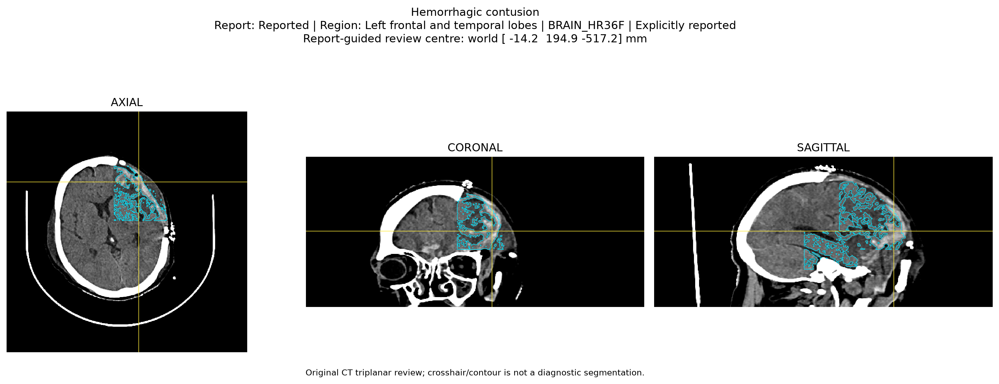

Acute subdural hematoma (SDH)


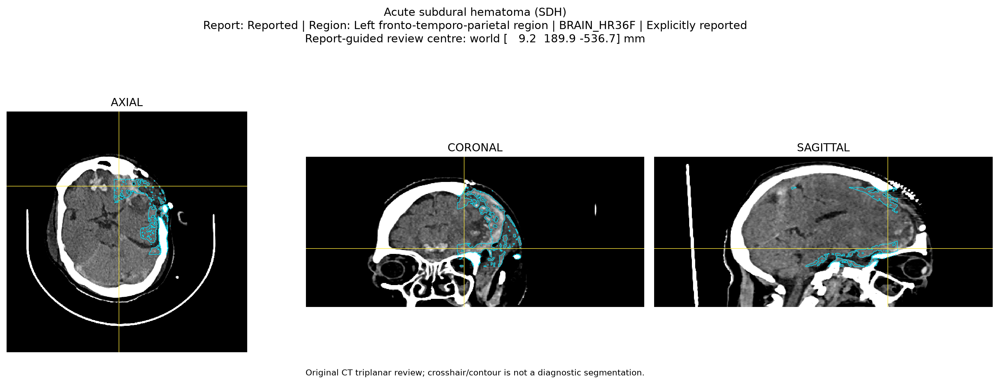

Posterior interhemispheric SDH


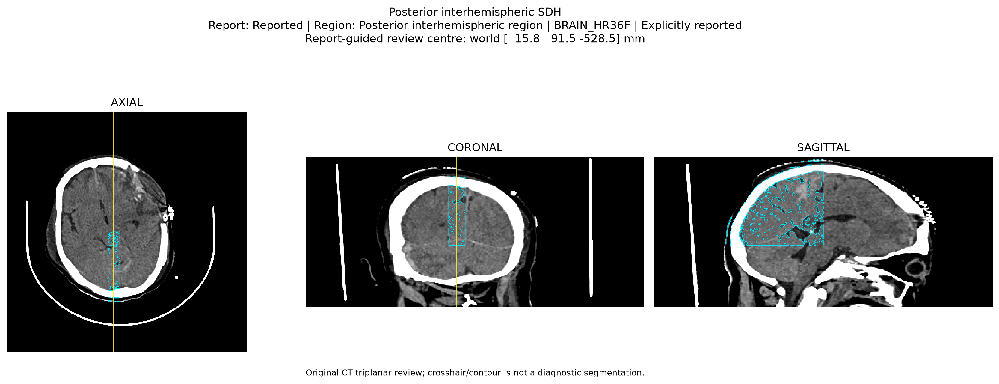

Intraventricular hemorrhage (IVH)


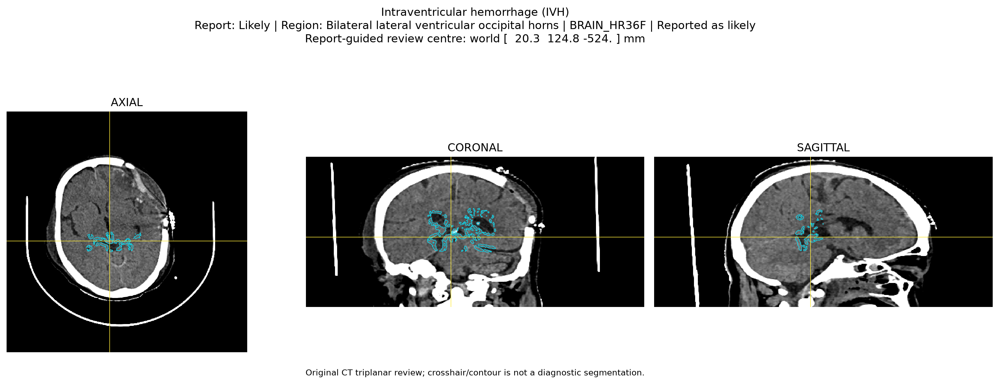

Subarachnoid hemorrhage (SAH)


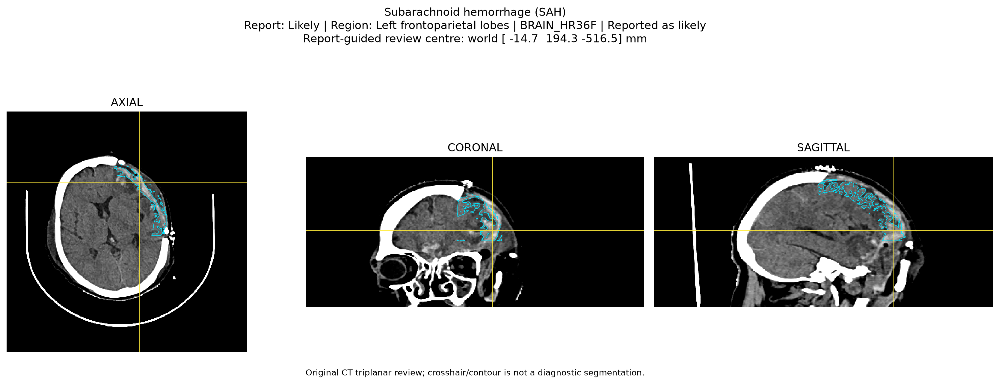

Mass effect / midline shift


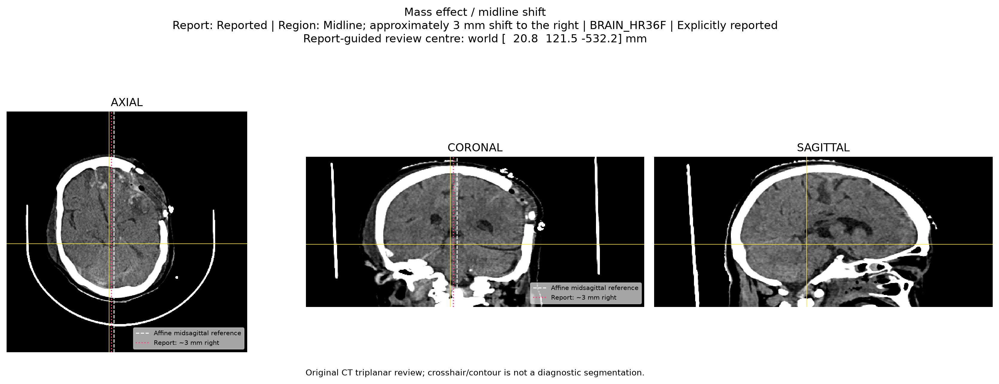

Postoperative extra-axial collection


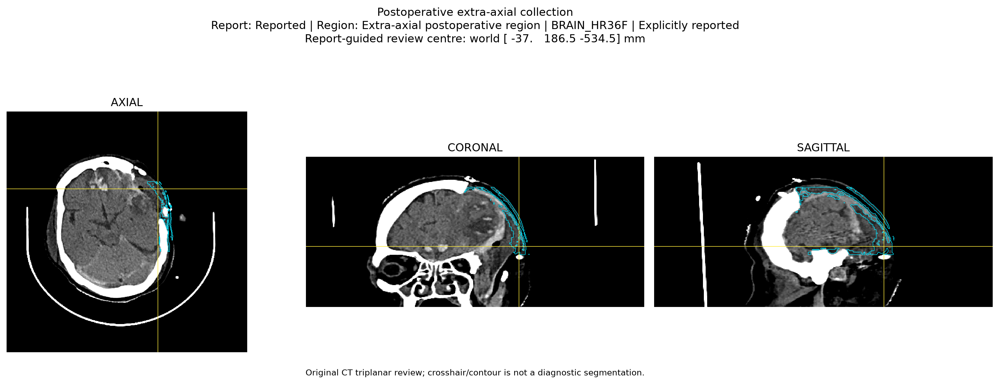

Right sphenoid bone fracture


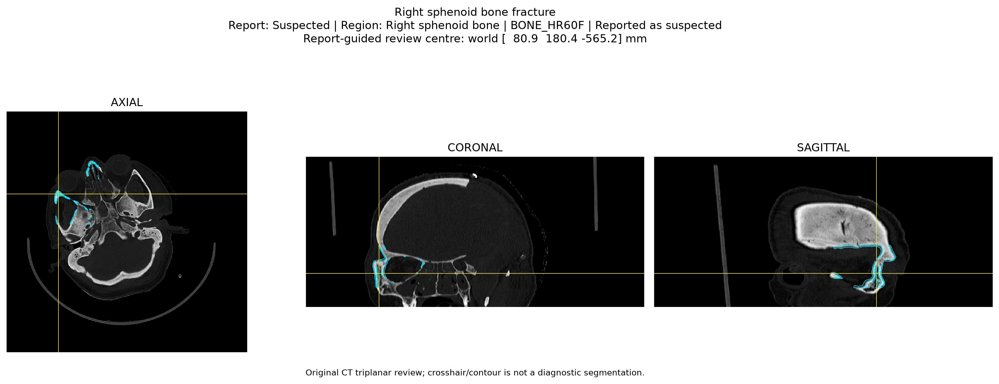

Right occipital bone fracture


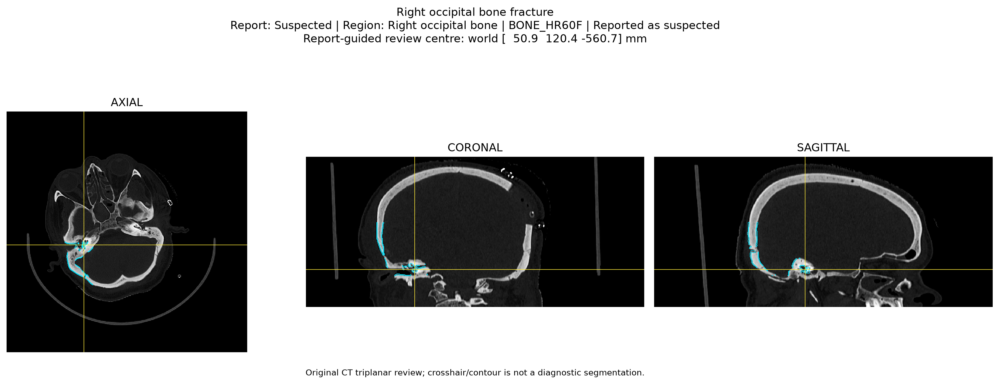

In [7]:
for v9_finding in v9_annotations["finding"]:
    print(v9_finding)
    display(Image(filename=str(v9_figure_paths[v9_finding])))

### 9.8 Machine-readable summary and interpretation limits

The JSON summary records all report rows and review coordinates without converting report-level findings into ground truth. A visual match or exploratory intensity candidate may support targeted review, but it cannot independently establish hemorrhage type, fracture, postoperative collection, or midline shift.

In [8]:
v9_summary = {
    "case": "CASE_001",
    "purpose": "Original CT triplanar review of structured report findings",
    "source_annotation": str(v9_annotation_path),
    "orientation_codes": list(v9_axcodes),
    "brain_reconstruction": str(v9_brain_ct_path),
    "bone_reconstruction": str(v9_bone_ct_path),
    "findings": v9_review_df.to_dict(orient="records"),
    "combined_figure": str(v9_combined_path),
    "interpretation_limitations": [
        "The structured CSV is report-level information, not voxel-level ground truth.",
        "Crosshairs are report-guided review centres rather than lesion centroids.",
        "Intensity candidates are nonspecific and do not independently diagnose hemorrhage.",
        "Bone-gradient candidates do not independently establish a fracture.",
        "The approximately 3 mm rightward line is a report-specified guide, not an automated shift measurement.",
        "Definitive confirmation and localization require expert radiological review."
    ],
}
v9_summary_path = v9_dir / "report_finding_triplanar_review_summary.json"
v9_summary_path.write_text(json.dumps(v9_summary, indent=2, ensure_ascii=False), encoding="utf-8")

print("-" * 68)
print("TRIPLANAR REVIEW OF STRUCTURED REPORT FINDINGS")
print("-" * 68)
print(f"Findings reviewed: {len(v9_review_df)}")
print("Planes generated for every finding: AXIAL, CORONAL, SAGITTAL")
print("Intracranial source: original BRAIN_HR36F CT")
print("Fracture source: original BONE_HR60F CT")
print(f"Individual figures: {len(v9_figure_paths)}")
print(f"Combined review sheet: {v9_combined_path}")
print(f"Review table: {v9_review_csv}")
print(f"Machine-readable summary: {v9_summary_path}")
print(
    "Interpretation: the images provide report-guided multiplanar review only. "
    "They are not voxel-level segmentations or independent diagnostic confirmation."
)
print("-" * 68)
print("Section 9 appended successfully; Sections 1–8 and all existing outputs were preserved.")

--------------------------------------------------------------------
TRIPLANAR REVIEW OF STRUCTURED REPORT FINDINGS
--------------------------------------------------------------------
Findings reviewed: 9
Planes generated for every finding: AXIAL, CORONAL, SAGITTAL
Intracranial source: original BRAIN_HR36F CT
Fracture source: original BONE_HR60F CT
Individual figures: 9
Combined review sheet: F:\csstdy\outputs\11_neural_ct_rendering\report_finding_triplanar_review\all_report_findings_triplanar_review.png
Review table: F:\csstdy\outputs\11_neural_ct_rendering\report_finding_triplanar_review\report_finding_triplanar_review.csv
Machine-readable summary: F:\csstdy\outputs\11_neural_ct_rendering\report_finding_triplanar_review\report_finding_triplanar_review_summary.json
Interpretation: the images provide report-guided multiplanar review only. They are not voxel-level segmentations or independent diagnostic confirmation.
--------------------------------------------------------------------
